# 02 Model Scientific Interest

Canonical modeling notebook for yearly scientific interest.
This notebook computes SI, ranks future high-interest pathogen-antibiotic pairs, and generates focused plots.
Set `ANTIBIOTIC_ANALYSIS_LEVEL` to `"antibiotic"` for individual antibiotics, or to a column in `assets/antibiotic_coarsening_lookup.csv` such as `"Class"`.


In [1]:
%load_ext autoreload
%autoreload 2


In [2]:
from pathlib import Path
import sys

from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "amr").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "amr").exists():
    raise RuntimeError(f"Could not find repository root from {Path.cwd()}")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from amr.pipelines.si import (
    DEFAULT_DRIVER_SUMMARY_COLUMNS,
    DEFAULT_DECREASING_SI_SUMMARY_COLUMNS,
    DEFAULT_SMOOTHED_SI_SHAPE_SUMMARY_COLUMNS,
    DEFAULT_INTERESTING_SUMMARY_COLUMNS,
    build_si_analysis_paths,
    build_si_driver_analysis,
    build_yearly_si_dataset,
    filter_model_inputs_by_average_amr_publications,
    load_yearly_si_inputs,
    prepare_antibiotic_analysis_level,
    print_si_dataset_summary,
    rank_future_high_interest_pairs,
    save_category_driver_plots,
    save_interesting_si_plots,
    save_smoothed_si_screen_plots,
    select_existing_columns,
    summarize_smoothed_si_shapes,
    select_smoothed_si_shape_cases,
    select_decreasing_smoothed_si_trends,
    summarize_pair_publication_rates,
    summarize_pathogen_coverage,
)
from amr.pipeline_config import cfg, cfg_path, load_pipeline_config


## Configuration


In [3]:
PIPELINE_CONFIG = load_pipeline_config(project_root=PROJECT_ROOT)

OUTPUT_DIR = cfg_path(PIPELINE_CONFIG, "paths.output_dir", PROJECT_ROOT)
PARQUET_OUTPUT_DIR = cfg_path(PIPELINE_CONFIG, "paths.parquet_dir", PROJECT_ROOT)
PARQUET_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR = PARQUET_OUTPUT_DIR

YEARLY_SCREENED_PATH = cfg_path(PIPELINE_CONFIG, "paths.yearly_screened", PROJECT_ROOT)
UNIFIED_DECISIONS_PATH = cfg_path(PIPELINE_CONFIG, "paths.unified_decisions", PROJECT_ROOT)
PATHOGEN_BG_PATH = cfg_path(PIPELINE_CONFIG, "paths.pathogen_background", PROJECT_ROOT)
ANTIBIOTIC_BG_PATH = cfg_path(PIPELINE_CONFIG, "paths.antibiotic_background", PROJECT_ROOT)
ANTIBIOTIC_COARSENING_PATH = cfg_path(PIPELINE_CONFIG, "paths.antibiotic_coarsening", PROJECT_ROOT)
DRIVER_CATEGORY_COARSENING_PATH = cfg_path(PIPELINE_CONFIG, "paths.driver_category_coarsening", PROJECT_ROOT)

# Analysis level controls antibiotic grouping for all SI model inputs and outputs.
ANTIBIOTIC_ANALYSIS_LEVEL = cfg(PIPELINE_CONFIG, "si.antibiotic_analysis_level")
SI_PATHS = build_si_analysis_paths(PROJECT_ROOT, ANTIBIOTIC_ANALYSIS_LEVEL)
YEARLY_SI_PATH = SI_PATHS["yearly_si"]
RANK_OUTPUT_PATH = SI_PATHS["rank_output"]
INTERESTING_OUTPUT_PATH = SI_PATHS["interesting_output"]
DRIVER_OUTPUT_PATH = SI_PATHS["driver_output"]
INTERESTING_PLOT_DIR = SI_PATHS["interesting_plot_dir"]
DRIVER_PLOT_DIR = SI_PATHS["driver_plot_dir"]
DECREASING_SI_OUTPUT_PATH = PARQUET_OUTPUT_DIR / "decreasing_smoothed_si_trends.parquet"
CONVEX_SI_OUTPUT_PATH = PARQUET_OUTPUT_DIR / "convex_u_shaped_smoothed_si_trends.parquet"
CONCAVE_SI_OUTPUT_PATH = PARQUET_OUTPUT_DIR / "concave_inverted_u_smoothed_si_trends.parquet"
DECREASING_SI_PLOT_DIR = OUTPUT_DIR / "figures" / "decreasing_smoothed_si_plots"
CONVEX_SI_PLOT_DIR = OUTPUT_DIR / "figures" / "convex_u_shaped_smoothed_si_plots"
CONCAVE_SI_PLOT_DIR = OUTPUT_DIR / "figures" / "concave_inverted_u_smoothed_si_plots"

# Fit/rank window controls.
FIT_START_YEAR = cfg(PIPELINE_CONFIG, "si.fit_start_year")
FIT_END_YEAR = cfg(PIPELINE_CONFIG, "si.fit_end_year")
CURVE_FIT_END_YEAR = cfg(PIPELINE_CONFIG, "si.curve_fit_end_year")
NUM_FUTURE_YEARS = cfg(PIPELINE_CONFIG, "si.num_future_years")
PLOT_END_YEAR = CURVE_FIT_END_YEAR + NUM_FUTURE_YEARS

# Pair filtering and interesting-pair ranking thresholds.
MIN_AVG_AMR_PUBLICATIONS_PER_YEAR = cfg(PIPELINE_CONFIG, "si.min_avg_amr_publications_per_year")
MIN_CURRENT_PREDICTED_COUNT = cfg(PIPELINE_CONFIG, "si.min_current_predicted_count")
MIN_FUTURE_PREDICTED_COUNT = cfg(PIPELINE_CONFIG, "si.min_future_predicted_count")
MIN_SI_CHANGE = cfg(PIPELINE_CONFIG, "si.min_si_change")
MIN_POST_FIT_OBSERVED_YEARS = cfg(PIPELINE_CONFIG, "si.min_post_fit_observed_years")
MAX_POST_FIT_SI_ABS_PCT_ERROR_MEAN = cfg(PIPELINE_CONFIG, "si.max_post_fit_si_abs_pct_error_mean")
MAX_SI_LOESS_RESIDUAL_VARIANCE_MEAN = cfg(PIPELINE_CONFIG, "si.max_si_loess_residual_variance_mean")
FALLBACK_TOP_N = cfg(PIPELINE_CONFIG, "si.fallback_top_n")

# Driver plots and display controls.
CATEGORY_INCLUDE_DECISIONS = tuple(cfg(PIPELINE_CONFIG, "si.category_include_decisions"))
DRIVER_CATEGORY_LEVEL = cfg(PIPELINE_CONFIG, "si.driver_category_level")
DRIVER_LOOKBACK_YEARS = cfg(PIPELINE_CONFIG, "si.driver_lookback_years")
MAX_DRIVER_PLOTS = cfg(PIPELINE_CONFIG, "si.max_driver_plots")
MAX_INTERESTING_PLOTS = cfg(PIPELINE_CONFIG, "si.max_interesting_plots")
FIGURE_FORMAT = cfg(PIPELINE_CONFIG, "si.figure_format")
DISPLAY_PLOTS = cfg(PIPELINE_CONFIG, "si.display_plots")
MAX_DISPLAY_PLOTS = cfg(PIPELINE_CONFIG, "si.max_display_plots")
FILL_MISSING_AMR_COUNTS_WITH_ZERO = cfg(PIPELINE_CONFIG, "si.fill_missing_amr_counts_with_zero")
LOESS_FRAC = cfg(PIPELINE_CONFIG, "si.loess_frac")
LOESS_DEGREE = cfg(PIPELINE_CONFIG, "si.loess_degree")
TAIL_DAMPING_YEARS = cfg(PIPELINE_CONFIG, "si.tail_damping_years")
SHAPE_SCREEN_PLOT_COUNT = cfg(PIPELINE_CONFIG, "si.shape_screen_plot_count")


## Load Canonical Inputs


In [4]:
yearly_screened_df, pathogen_bg_df, antibiotic_bg_df, unified_decisions_df = load_yearly_si_inputs(
    yearly_screened_path=YEARLY_SCREENED_PATH,
    pathogen_background_path=PATHOGEN_BG_PATH,
    antibiotic_background_path=ANTIBIOTIC_BG_PATH,
    unified_decisions_path=UNIFIED_DECISIONS_PATH,
)


yearly_screened rows: 14,220
yearly_screened unique pathogens: 48
yearly_screened unique antibiotics: 191
yearly_screened year range: 2000 - 2022
pathogen bg rows: 1,296
antibiotic bg rows: 5,319
unified decision rows available for driver analysis: 107,950


## Prepare Antibiotic Analysis Level

This step optionally aggregates from individual antibiotics to a selected coarsening column before SI modeling.


In [5]:
yearly_screened_model_df, antibiotic_bg_model_df, unified_decisions_model_df, analysis_summary = prepare_antibiotic_analysis_level(
    yearly_screened_df=yearly_screened_df,
    antibiotic_background_df=antibiotic_bg_df,
    unified_decisions_df=unified_decisions_df,
    coarsening_path=ANTIBIOTIC_COARSENING_PATH,
    analysis_level=ANTIBIOTIC_ANALYSIS_LEVEL,
)

yearly_screened_model_df.head(10)


Antibiotic analysis level: individual antibiotic.
model yearly rows: 14,220
model pathogen-antibiotic rows: 2,368
model antibiotic values: 191
model antibiotic background rows: 5,319
model unified decision rows: 107,950


,pathogen,antibiotic,year,pmids,count
0,Acinetobacter baumannii,Amikacin,2003,"[12872781, 14748260]",2
1,Acinetobacter baumannii,Amikacin,2005,"[16103700, 16258323]",2
2,Acinetobacter baumannii,Amikacin,2006,"[16597632, 16776825]",2
3,Acinetobacter baumannii,Amikacin,2008,"[18261233, 18792817]",2
4,Acinetobacter baumannii,Amikacin,2009,"[19795613, 19949755, 20583564]",3
5,Acinetobacter baumannii,Amikacin,2010,"[20028819, 20107089, 20186407, 20194701, 20499...",9
6,Acinetobacter baumannii,Amikacin,2011,"[21803697, 22016680, 22122819]",3
7,Acinetobacter baumannii,Amikacin,2012,"[22104303, 22154196, 22461312, 22579564, 22808...",6
8,Acinetobacter baumannii,Amikacin,2013,"[23400749, 23435692, 23660097, 23668462, 23676...",9
9,Acinetobacter baumannii,Amikacin,2014,"[23726465, 24235096, 24607428, 24653812, 24985...",10


## Build Yearly SI Dataset


## Filter Low-Volume Pairs

Keep only pathogen-antibiotic pairs with enough screened AMR publications on average across the fitting window. The average includes years with zero publications.


In [6]:
yearly_screened_model_unfiltered_df = yearly_screened_model_df.copy()

yearly_screened_model_df, unified_decisions_model_df, pair_publication_rates = filter_model_inputs_by_average_amr_publications(
    yearly_screened_model_df=yearly_screened_model_df,
    unified_decisions_model_df=unified_decisions_model_df,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    min_avg_amr_publications_per_year=MIN_AVG_AMR_PUBLICATIONS_PER_YEAR,
)

pathogen_filter_summary_df = summarize_pathogen_coverage(
    source_df=yearly_screened_model_unfiltered_df,
    modeled_df=yearly_screened_model_df,
    source_label="model input before publication filter",
    modeled_label="model input after publication filter",
)

display(pathogen_filter_summary_df.query("status != 'present_in_both'"))
summarize_pair_publication_rates(pair_publication_rates, head=30)


AMR publication filter: kept 363 / 2,368 pairs with >= 1 publications/year on average from 2000 to 2023.
model input before publication filter pathogens: 48
model input after publication filter pathogens: 25
Pathogens present in model input before publication filter but absent from model input after publication filter: 23
Aggregatibacter actinomycetemcomitans, Bacillus anthracis, Bordetella pertussis, Borrelia burgdorferi, Brucella melitensis, Burkholderia cepacia, Burkholderia pseudomallei, Chlamydia pneumoniae, Chlamydia trachomatis, Coxiella burnetii, Francisella tularensis, Legionella pneumophila, Moraxella catarrhalis, Mycobacterium abscessus, Mycobacterium avium, Mycobacterium leprae, Mycoplasmoides pneumoniae, Neisseria meningitidis, Orientia tsutsugamushi, Porphyromonas gingivalis, Treponema pallidum, Yersinia enterocolitica, Yersinia pestis


,pathogen,source_rows,source_publications,source_pairs,modeled_rows,modeled_publications,modeled_pairs,in_source,in_modeled,status
0,Aggregatibacter actinomycetemcomitans,60,36,15,0.0,0.0,0.0,True,False,missing_from_modeled
1,Bacillus anthracis,41,31,30,0.0,0.0,0.0,True,False,missing_from_modeled
2,Bordetella pertussis,30,20,11,0.0,0.0,0.0,True,False,missing_from_modeled
3,Borrelia burgdorferi,21,18,14,0.0,0.0,0.0,True,False,missing_from_modeled
4,Brucella melitensis,68,48,24,0.0,0.0,0.0,True,False,missing_from_modeled
5,Burkholderia cepacia,123,89,38,0.0,0.0,0.0,True,False,missing_from_modeled
6,Burkholderia pseudomallei,91,90,30,0.0,0.0,0.0,True,False,missing_from_modeled
7,Chlamydia pneumoniae,28,22,20,0.0,0.0,0.0,True,False,missing_from_modeled
8,Chlamydia trachomatis,75,54,31,0.0,0.0,0.0,True,False,missing_from_modeled
9,Coxiella burnetii,6,3,4,0.0,0.0,0.0,True,False,missing_from_modeled


,pathogen,antibiotic,fit_window_amr_publications,avg_amr_publications_per_year
1791,Staphylococcus aureus,Meticillin,2453,102.208333
694,Escherichia coli,Ampicillin,920,38.333333
837,Escherichia coli,Tetracycline,841,35.041667
742,Escherichia coli,Ciprofloxacin,772,32.166667
1844,Staphylococcus aureus,Vancomycin,705,29.375000
843,Escherichia coli,Trimethoprim,618,25.750000
952,Helicobacter pylori,Clarithromycin,562,23.416667
826,Escherichia coli,Sulfamethoxazole,513,21.375000
827,Escherichia coli,Sulfamethoxazole/trimethoprim,474,19.750000
1773,Staphylococcus aureus,Erythromycin,446,18.583333


In the next code cell, the notebook combines the screened yearly AMR counts with background publication counts to calculate a scientific-interest score for each pathogen-antibiotic-year. In simple terms, it estimates how much attention each pair is getting beyond what would be expected from general research activity alone, then saves those results for ranking and forecasting in later steps.


In [7]:
si_df, pooled_model, design_columns = build_yearly_si_dataset(
    yearly_screened_model_df,
    pathogen_bg_df,
    antibiotic_bg_model_df,
    output_path=YEARLY_SI_PATH,
)

print_si_dataset_summary(si_df)
si_pathogen_summary_df = summarize_pathogen_coverage(
    source_df=yearly_screened_model_df,
    modeled_df=si_df,
    source_label="filtered model input",
    modeled_label="yearly SI output",
)
display(si_pathogen_summary_df.query("status != 'present_in_both'"))
si_df.head(10)


SI rows: 6,611
SI pairs: 363
SI pathogens: 25
filtered model input pathogens: 25
yearly SI output pathogens: 25


,pathogen,source_rows,source_publications,source_pairs,modeled_rows,modeled_publications,modeled_pairs,in_source,in_modeled,status


,pathogen,antibiotic,year,pmids,count,bg_pathogen_n,bg_antibiotic_n,log_count,log_bg_pathogen_n,log_bg_antibiotic_n,expected_log_count_global,expected_count_global,SI
0,Acinetobacter baumannii,Amikacin,2003,"[12872781, 14748260]",2,80,183,0.477121,1.908485,2.264818,0.443828,1.778612,0.033293
1,Acinetobacter baumannii,Amikacin,2005,"[16103700, 16258323]",2,139,187,0.477121,2.146128,2.274158,0.514783,2.271773,-0.037662
2,Acinetobacter baumannii,Amikacin,2006,"[16597632, 16776825]",2,176,194,0.477121,2.247973,2.290035,0.543412,2.494713,-0.066290
3,Acinetobacter baumannii,Amikacin,2008,"[18261233, 18792817]",2,247,228,0.477121,2.394452,2.359835,0.577544,2.780453,-0.100423
4,Acinetobacter baumannii,Amikacin,2009,"[19795613, 19949755, 20583564]",3,287,256,0.602060,2.459392,2.409933,0.589805,2.888703,0.012255
5,Acinetobacter baumannii,Amikacin,2010,"[20028819, 20107089, 20186407, 20194701, 20499...",9,342,265,1.000000,2.535294,2.424882,0.610673,3.080123,0.389327
6,Acinetobacter baumannii,Amikacin,2011,"[21803697, 22016680, 22122819]",3,421,266,0.602060,2.625312,2.426511,0.637837,3.343471,-0.035777
7,Acinetobacter baumannii,Amikacin,2012,"[22104303, 22154196, 22461312, 22579564, 22808...",6,495,294,0.845098,2.695482,2.469822,0.652707,3.494768,0.192391
8,Acinetobacter baumannii,Amikacin,2013,"[23400749, 23435692, 23660097, 23668462, 23676...",9,511,368,1.000000,2.709270,2.567026,0.642330,3.388643,0.357670
9,Acinetobacter baumannii,Amikacin,2014,"[23726465, 24235096, 24607428, 24653812, 24985...",10,640,394,1.041393,2.806858,2.596597,0.667609,3.651673,0.373784


## Rank Reliable Future High-Interest Pairs


In [8]:
rank_df, interesting_df = rank_future_high_interest_pairs(
    si_df,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    min_current_predicted_count=MIN_CURRENT_PREDICTED_COUNT,
    min_future_predicted_count=MIN_FUTURE_PREDICTED_COUNT,
    min_si_change=MIN_SI_CHANGE,
    min_post_fit_observed_years=MIN_POST_FIT_OBSERVED_YEARS,
    max_post_fit_si_abs_pct_error_mean=MAX_POST_FIT_SI_ABS_PCT_ERROR_MEAN,
    max_si_loess_residual_variance_mean=MAX_SI_LOESS_RESIDUAL_VARIANCE_MEAN,
    fallback_top_n=FALLBACK_TOP_N,
    rank_output_path=RANK_OUTPUT_PATH,
    interesting_output_path=INTERESTING_OUTPUT_PATH,
    verbose=True,
)

select_existing_columns(
    interesting_df,
    DEFAULT_INTERESTING_SUMMARY_COLUMNS,
    head=30,
)


[1/363] ranking Acinetobacter baumannii vs Amikacin
[2/363] ranking Acinetobacter baumannii vs Ampicillin
[3/363] ranking Acinetobacter baumannii vs Ampicillin/sulbactam
[4/363] ranking Acinetobacter baumannii vs Aztreonam
[5/363] ranking Acinetobacter baumannii vs Cefepime
[6/363] ranking Acinetobacter baumannii vs Cefoperazone
[7/363] ranking Acinetobacter baumannii vs Cefotaxime
[8/363] ranking Acinetobacter baumannii vs Ceftazidime
[9/363] ranking Acinetobacter baumannii vs Ceftolozane/tazobactam
[10/363] ranking Acinetobacter baumannii vs Ceftriaxone
[11/363] ranking Acinetobacter baumannii vs Chloramphenicol
[12/363] ranking Acinetobacter baumannii vs Ciprofloxacin
[13/363] ranking Acinetobacter baumannii vs Colistin
[14/363] ranking Acinetobacter baumannii vs Gentamicin
[15/363] ranking Acinetobacter baumannii vs Levofloxacin
[16/363] ranking Acinetobacter baumannii vs Meropenem
[17/363] ranking Acinetobacter baumannii vs Meticillin
[18/363] ranking Acinetobacter baumannii vs Mi

,pathogen,antibiotic,interest_score,si_change,current_predicted_count,future_predicted_count,si_loess_residual_variance_mean,post_fit_si_abs_pct_error_mean
0,Pseudomonas aeruginosa,Ceftazidime/avibactam,1.378556,1.865454,246.641689,17657.832239,0.066121,NaN
1,Vibrio parahaemolyticus,Ampicillin,0.954150,1.397037,110.979651,2735.678397,0.071906,NaN
2,Neisseria gonorrhoeae,Gentamicin,0.555061,0.918459,35.743742,319.193519,0.033185,NaN
3,Haemophilus influenzae,Amoxicillin/clavulanic-acid,0.366042,0.605647,35.765241,133.535409,0.053800,NaN
4,Salmonella enterica,Azithromycin,0.354851,0.602340,28.615929,103.978111,0.079534,NaN
5,Acinetobacter baumannii,Sulfamethoxazole,0.344293,0.657932,10.653246,56.341707,0.040999,NaN
6,Listeria monocytogenes,Gentamicin,0.317629,0.602414,11.326684,49.322510,0.053757,NaN
7,Salmonella enterica,Colistin,0.311995,0.552539,19.940326,73.877200,0.054170,NaN
8,Klebsiella pneumoniae,Polymyxin-B,0.200256,0.382635,10.663731,31.312694,0.050806,NaN
9,Pseudomonas aeruginosa,Ceftolozane/tazobactam,0.093325,0.178044,10.797838,18.220689,0.114019,NaN


## Explain Predicted SI Changes

This section uses the LLM category metadata from the unified abstract screen to describe which AMR paper types are driving the observed count curves behind the SI forecast. The analysis is descriptive: it explains category mix and recent changes, while the ranking itself remains based on the screened yearly AMR counts.


In [9]:
category_counts_df, interesting_with_drivers_df = build_si_driver_analysis(
    interesting_df=interesting_df,
    unified_decisions_df=unified_decisions_model_df,
    fit_end_year=FIT_END_YEAR,
    include_decisions=CATEGORY_INCLUDE_DECISIONS,
    lookback_years=DRIVER_LOOKBACK_YEARS,
    output_path=DRIVER_OUTPUT_PATH,
)

select_existing_columns(
    interesting_with_drivers_df,
    DEFAULT_DRIVER_SUMMARY_COLUMNS,
    head=30,
)


Saved SI driver explanations to /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/parquets/yearly_si_driver_explanations.parquet


,pathogen,antibiotic,interest_score,si_change,current_predicted_count,future_predicted_count,driver_recent_total,driver_count_change,driver_dominant_category,driver_fastest_growing_category,driver_weak_signal_share,driver_target_pair_supported_share
0,Pseudomonas aeruginosa,Ceftazidime/avibactam,1.378556,1.865454,246.641689,17657.832239,10,10,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,0.0,1.0
1,Vibrio parahaemolyticus,Ampicillin,0.954150,1.397037,110.979651,2735.678397,16,14,SURVEILLANCE,SURVEILLANCE,0.0,1.0
2,Neisseria gonorrhoeae,Gentamicin,0.555061,0.918459,35.743742,319.193519,11,10,SURVEILLANCE,SURVEILLANCE,0.0,1.0
3,Haemophilus influenzae,Amoxicillin/clavulanic-acid,0.366042,0.605647,35.765241,133.535409,0,0,None,None,0.0,0.0
4,Salmonella enterica,Azithromycin,0.354851,0.602340,28.615929,103.978111,27,23,SURVEILLANCE,SURVEILLANCE,0.0,1.0
5,Acinetobacter baumannii,Sulfamethoxazole,0.344293,0.657932,10.653246,56.341707,9,7,SURVEILLANCE,SURVEILLANCE,0.0,1.0
6,Listeria monocytogenes,Gentamicin,0.317629,0.602414,11.326684,49.322510,6,4,SURVEILLANCE,SURVEILLANCE,0.0,1.0
7,Salmonella enterica,Colistin,0.311995,0.552539,19.940326,73.877200,17,14,SURVEILLANCE,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,0.0,1.0
8,Klebsiella pneumoniae,Polymyxin-B,0.200256,0.382635,10.663731,31.312694,11,10,SURVEILLANCE,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,0.0,1.0
9,Pseudomonas aeruginosa,Ceftolozane/tazobactam,0.093325,0.178044,10.797838,18.220689,20,17,SURVEILLANCE,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,0.0,1.0


## Plot Category Driver Curves


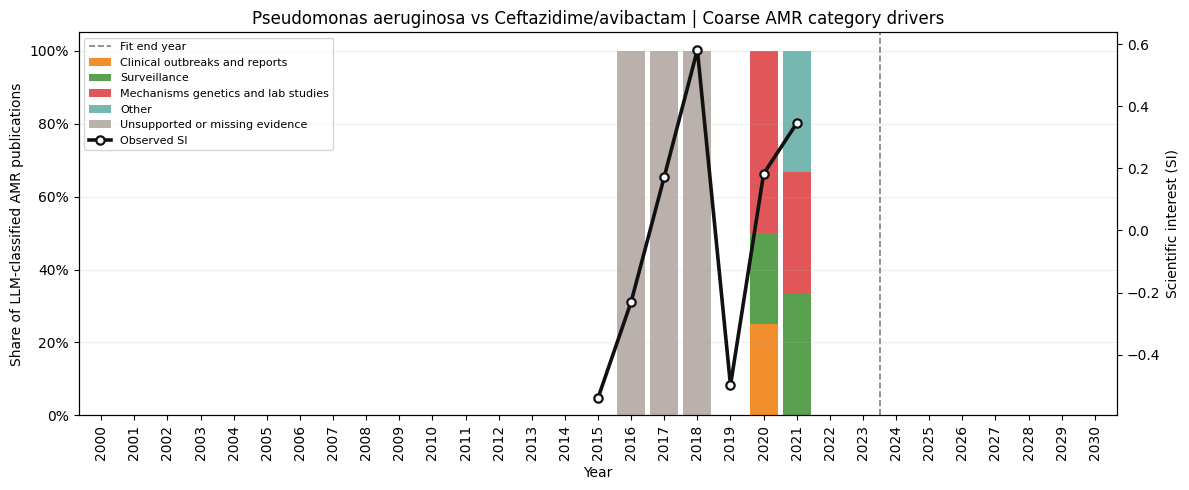

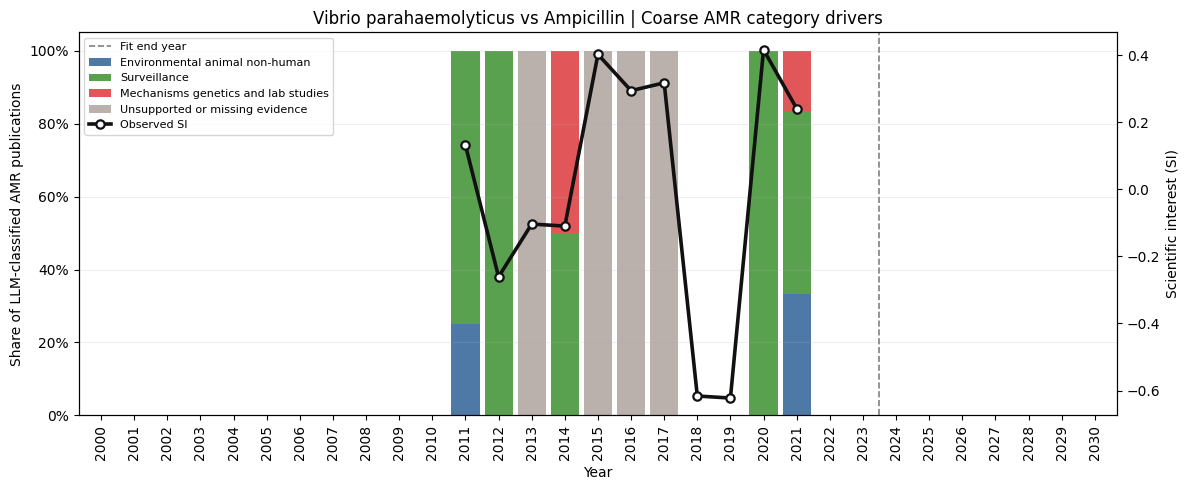

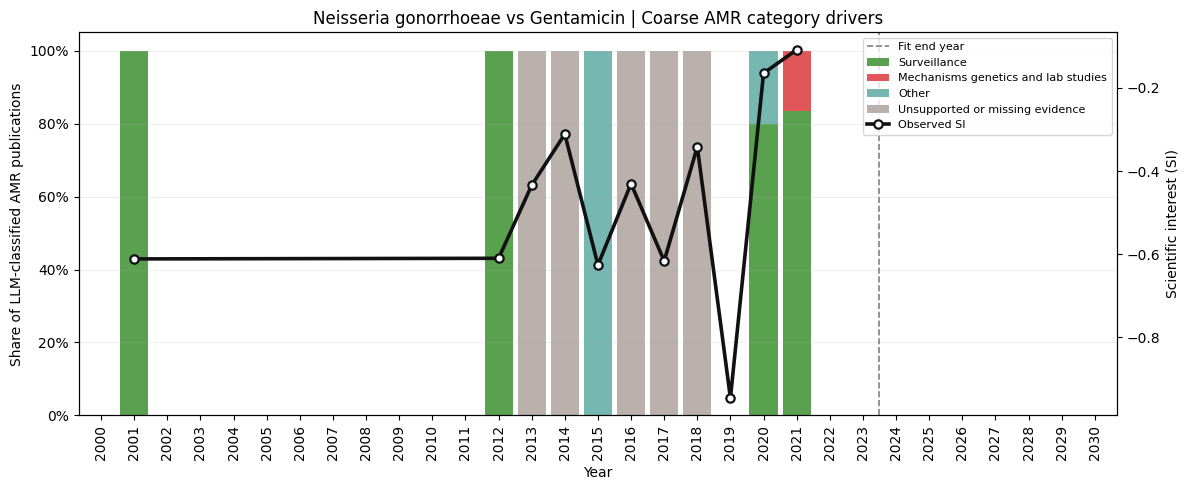

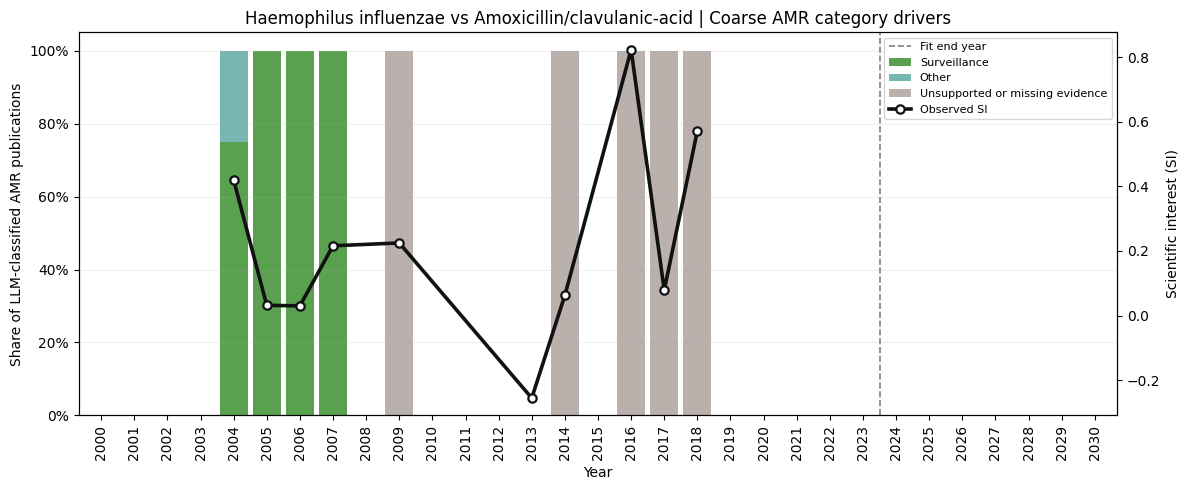

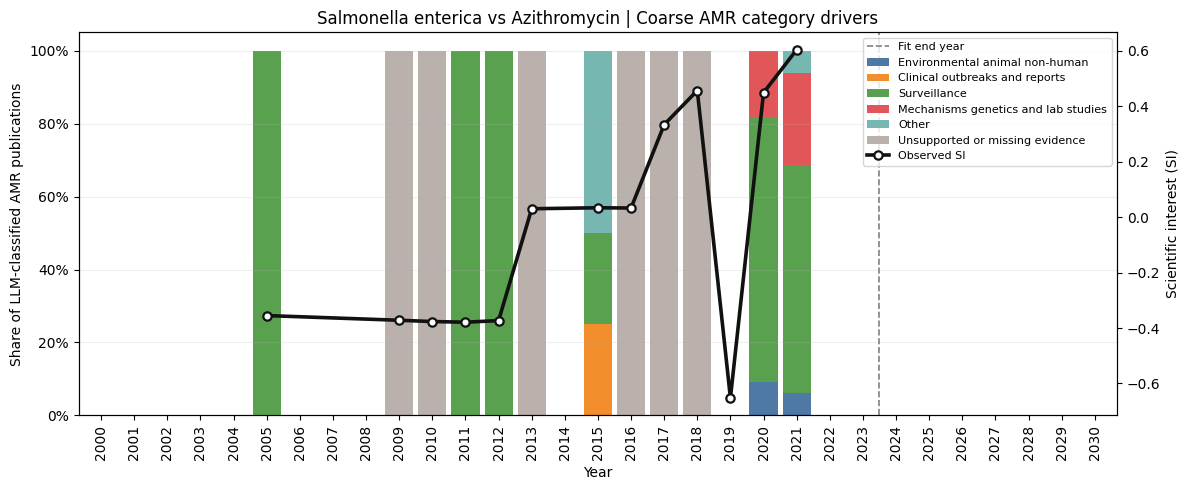

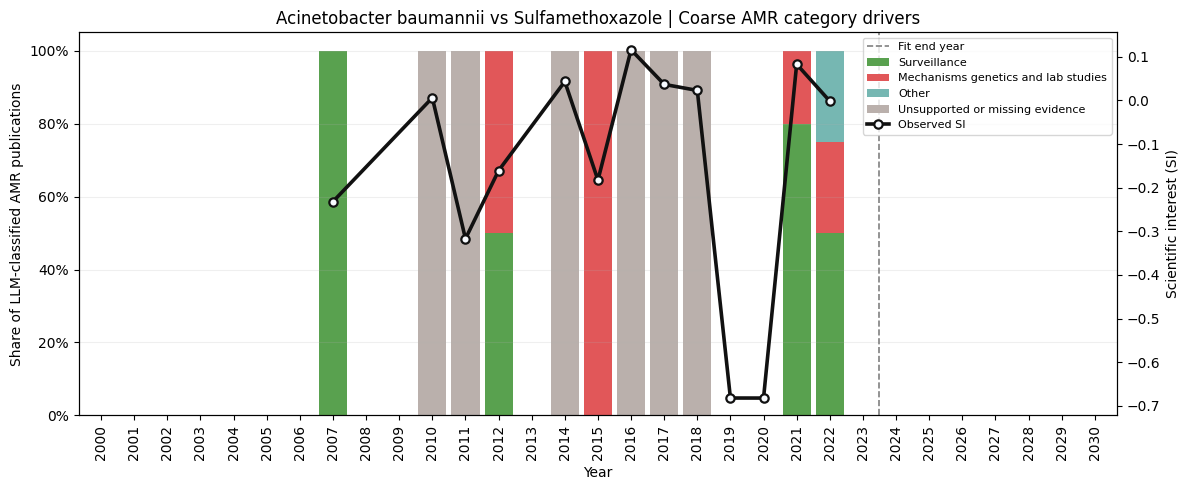

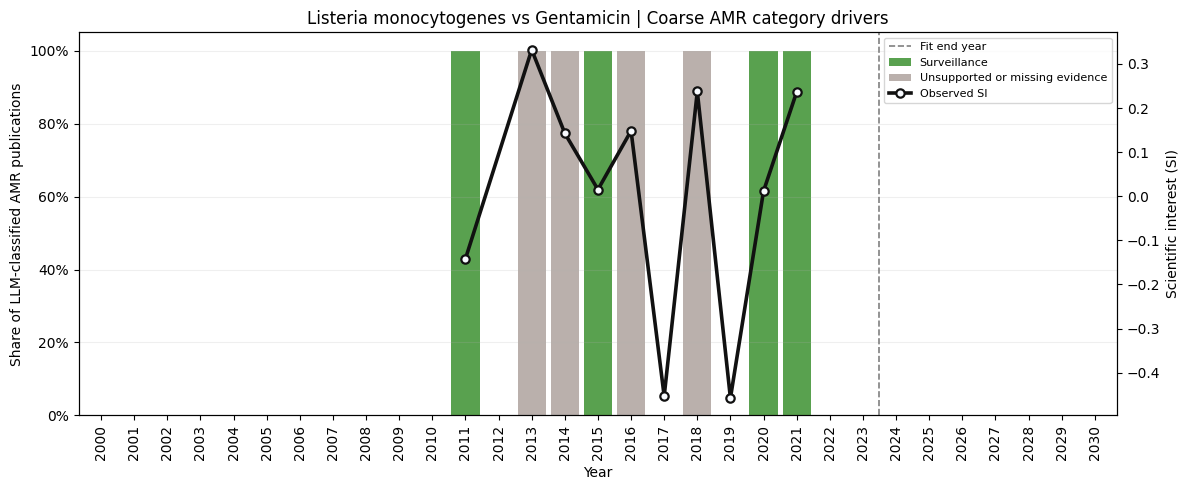

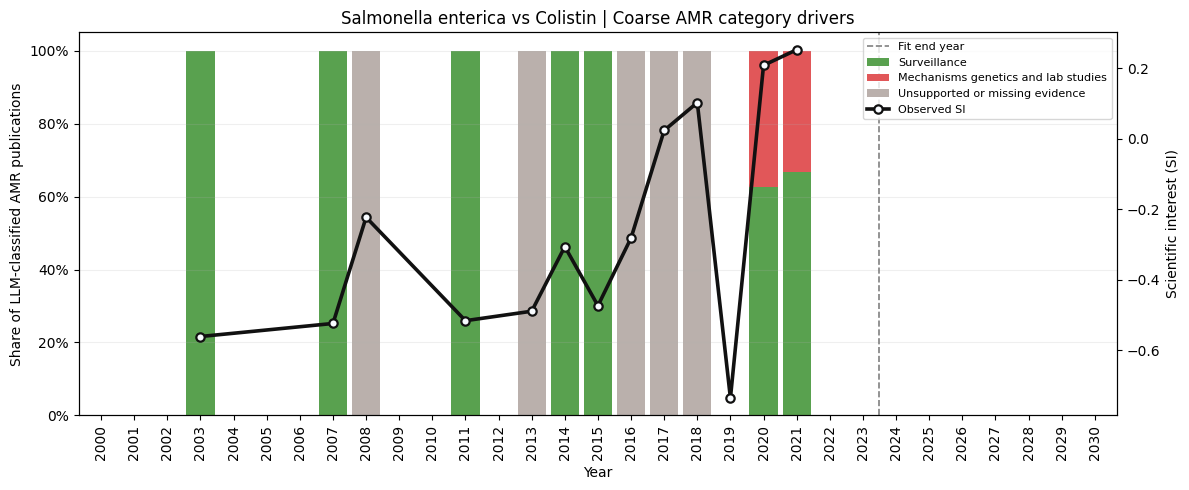

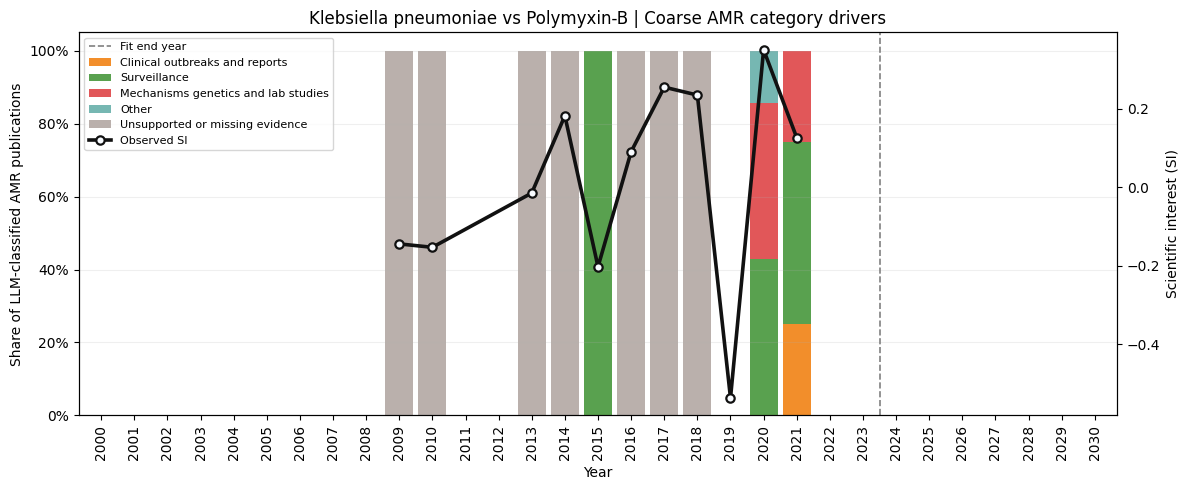

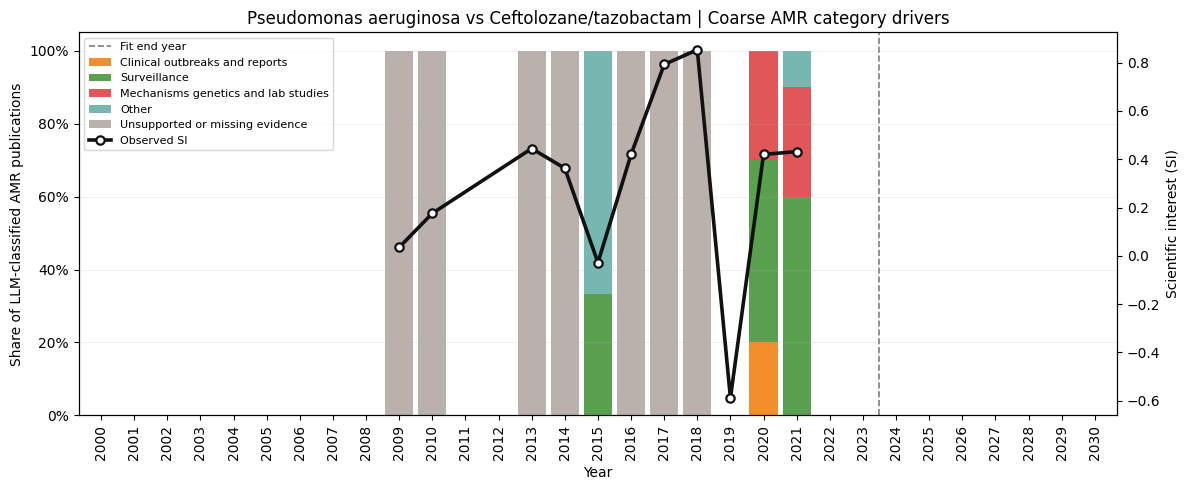

Saved 12 coarse category driver plots to /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/figures/interesting_yearly_si_driver_plots
Displayed 10 category driver plots inline.


In [10]:
saved_driver_plots = save_category_driver_plots(
    category_counts_df=category_counts_df,
    si_df=si_df,
    interesting_df=interesting_df,
    output_dir=DRIVER_PLOT_DIR,
    start_year=FIT_START_YEAR,
    end_year=PLOT_END_YEAR,
    fit_end_year=FIT_END_YEAR,
    max_plots=MAX_DRIVER_PLOTS,
    figure_format=FIGURE_FORMAT,
    driver_category_level=DRIVER_CATEGORY_LEVEL,
    category_coarsening_path=DRIVER_CATEGORY_COARSENING_PATH,
    display_plots=DISPLAY_PLOTS,
    max_display_plots=MAX_DISPLAY_PLOTS,
)


## Plot Top Interesting Pairs


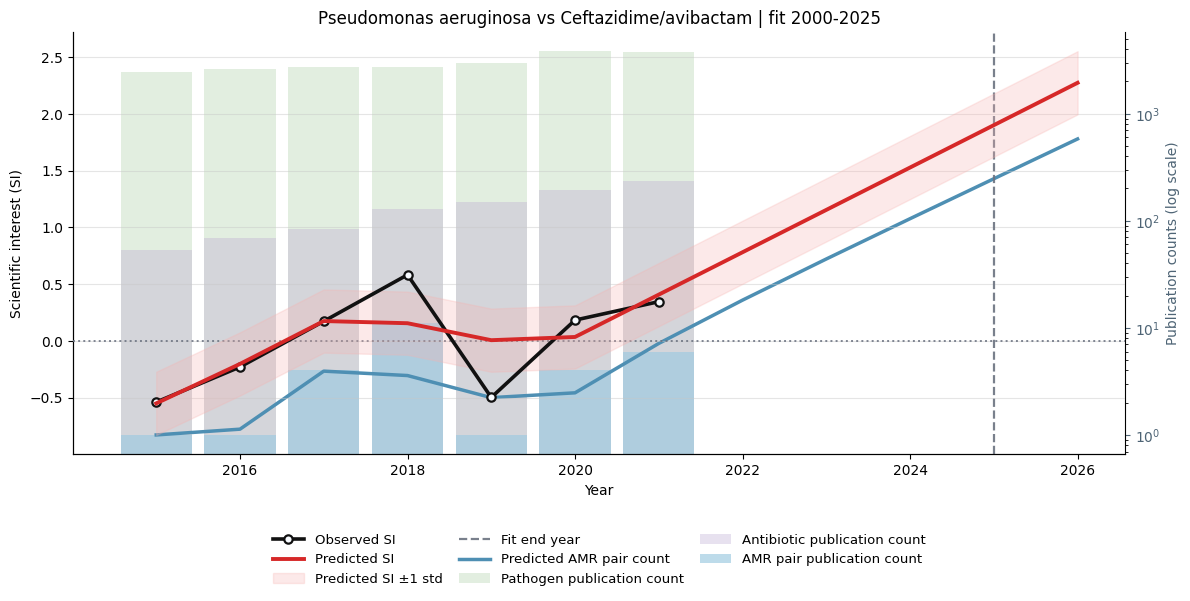

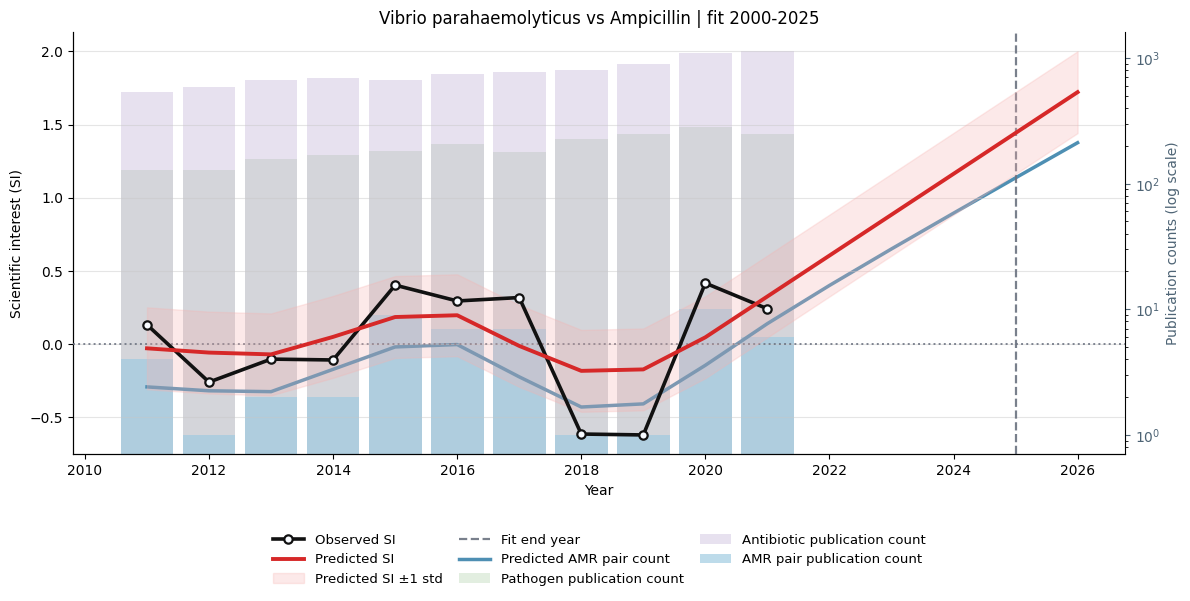

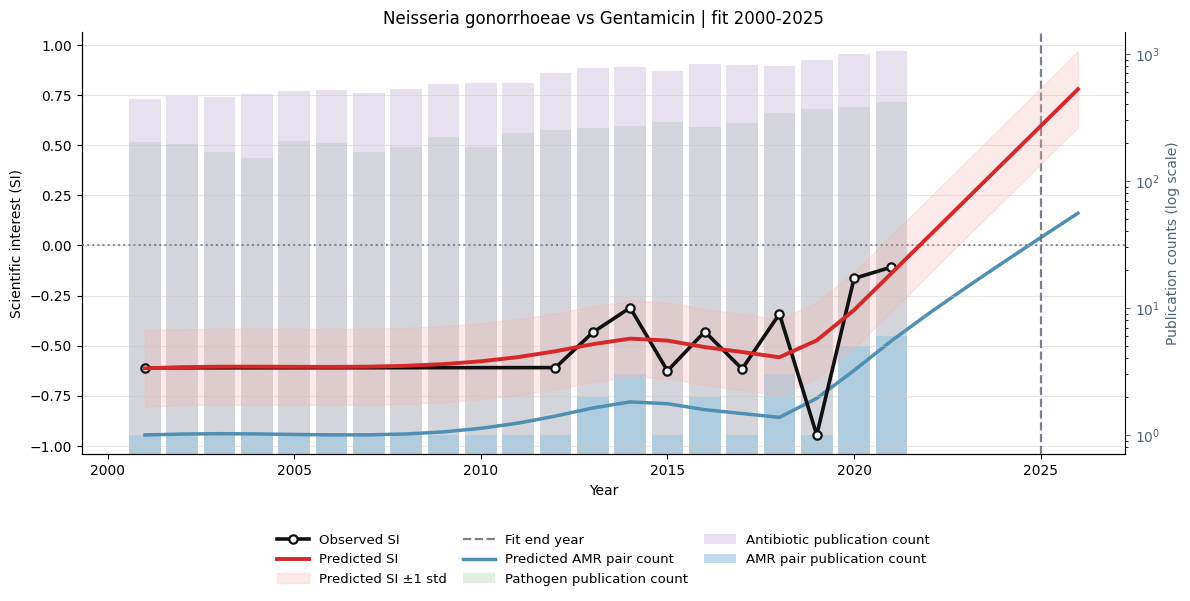

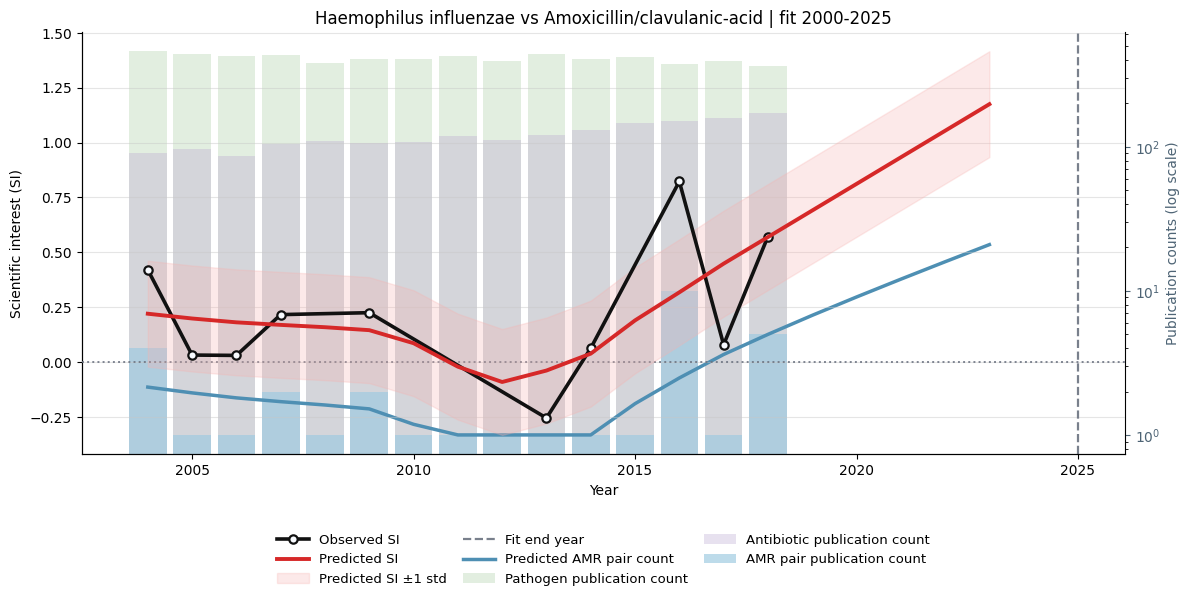

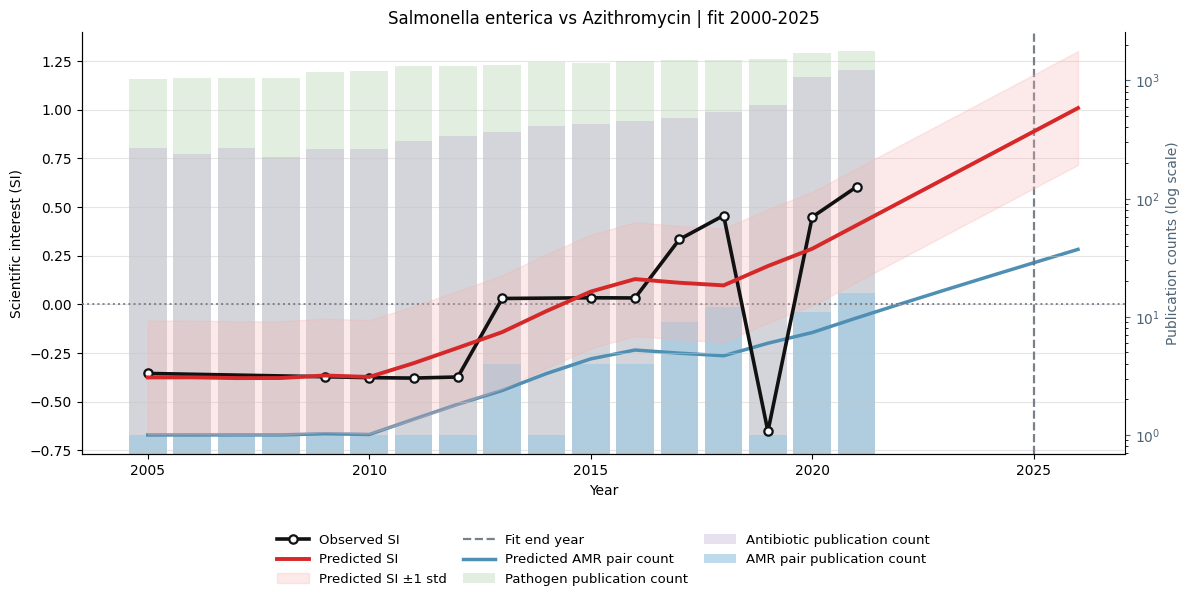

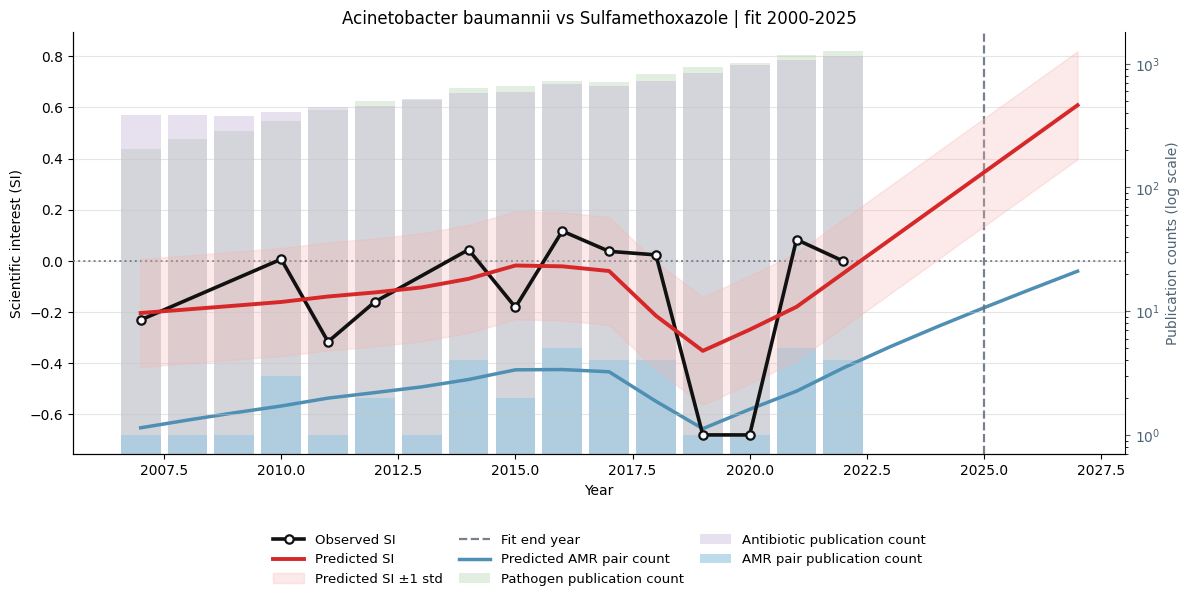

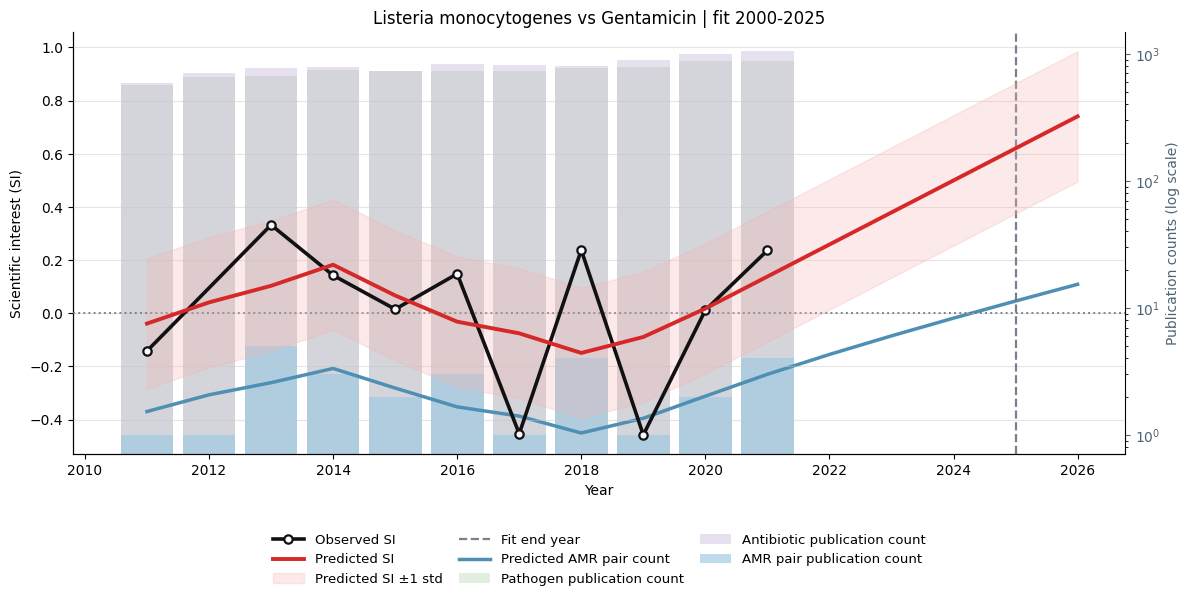

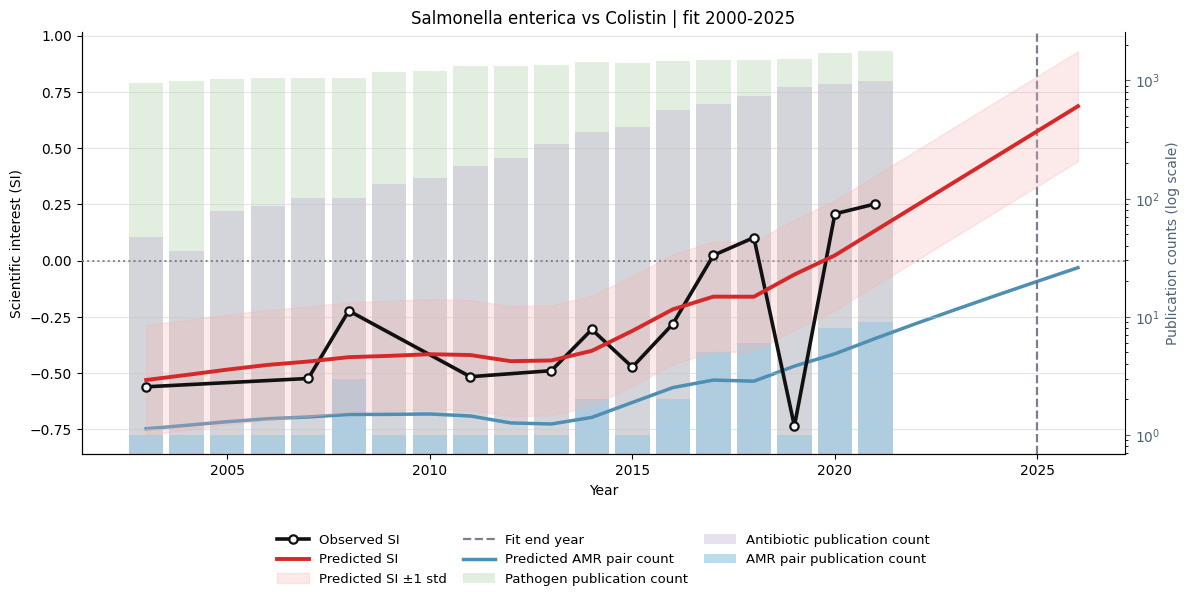

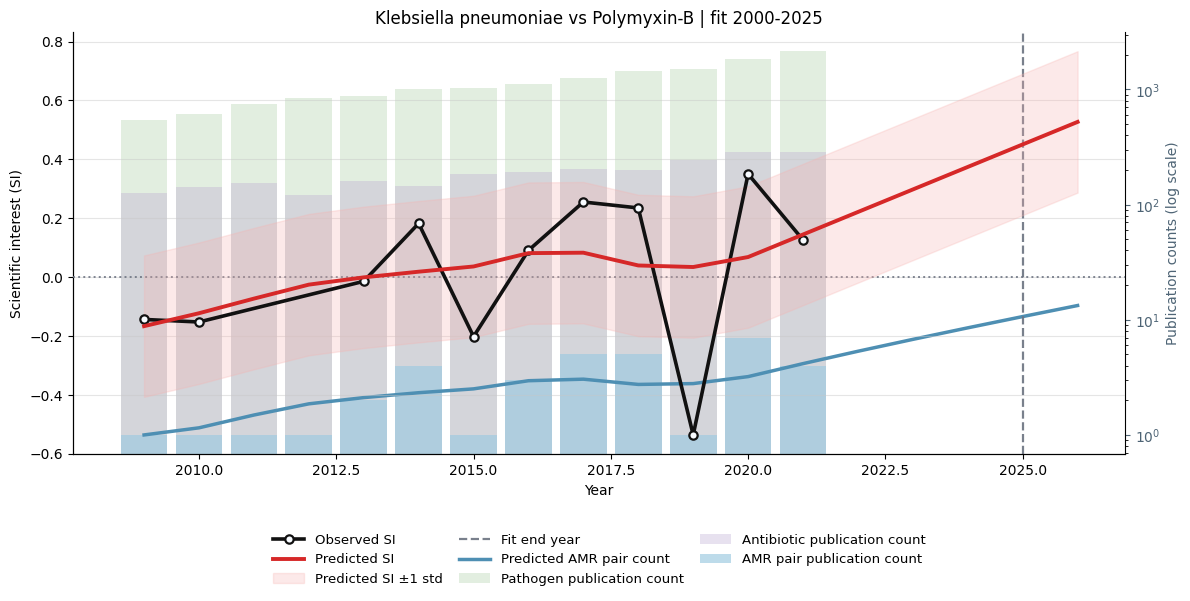

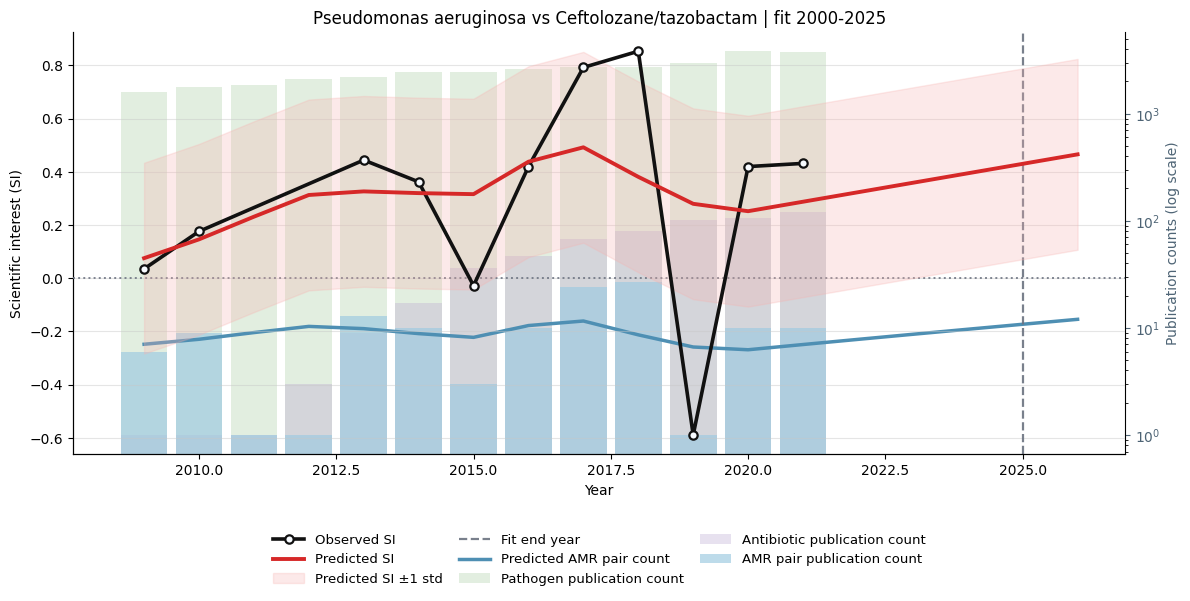

Saved 12 plots to /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/figures/interesting_yearly_si_plots
Displayed 10 plots inline.


In [11]:
saved_interesting_plots = save_interesting_si_plots(
    si_df=si_df,
    interesting_df=interesting_df,
    output_dir=INTERESTING_PLOT_DIR,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    pathogen_background_df=pathogen_bg_df,
    antibiotic_background_df=antibiotic_bg_model_df,
    max_plots=MAX_INTERESTING_PLOTS,
    loess_frac=0.6,
    loess_degree=1,
    tail_damping_years=None,
    fill_missing_amr_counts_with_zero=FILL_MISSING_AMR_COUNTS_WITH_ZERO,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
    max_display_plots=MAX_DISPLAY_PLOTS,
)


## Additional SI Shape Screens


### Largest Decreasing Smoothed SI Trends


In [12]:
decreasing_smoothed_si_df = select_decreasing_smoothed_si_trends(
    rank_df,
    output_path=DECREASING_SI_OUTPUT_PATH,
)

select_existing_columns(
    decreasing_smoothed_si_df,
    DEFAULT_DECREASING_SI_SUMMARY_COLUMNS,
    head=10,
)


Saved decreasing smoothed SI table: 314 rows -> /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/parquets/decreasing_smoothed_si_trends.parquet


,pathogen,antibiotic,reference_year,future_year,current_predicted_SI,future_predicted_SI,si_change,current_predicted_count,future_predicted_count,si_loess_residual_variance_mean,post_fit_si_abs_pct_error_mean
0,Klebsiella pneumoniae,Ceftazidime/avibactam,2025,2030,-1.721703,-3.659640,-1.937937,0.0,0.0,0.100550,NaN
1,Pseudomonas aeruginosa,Meticillin,2025,2030,-2.483154,-4.144336,-1.661182,0.0,0.0,0.128434,NaN
2,Escherichia coli,Ampicillin,2025,2030,-2.028444,-3.622592,-1.594148,0.0,0.0,0.121914,NaN
3,Escherichia coli,Ciprofloxacin,2025,2030,-2.027665,-3.583158,-1.555493,0.0,0.0,0.107750,NaN
4,Klebsiella pneumoniae,Meticillin,2025,2030,-2.202016,-3.626895,-1.424879,0.0,0.0,0.094459,NaN
5,Escherichia coli,Sulfamethoxazole,2025,2030,-1.800479,-3.184255,-1.383776,0.0,0.0,0.104552,NaN
6,Escherichia coli,Sulfamethoxazole/trimethoprim,2025,2030,-1.783945,-3.145945,-1.362000,0.0,0.0,0.102039,NaN
7,Escherichia coli,Gentamicin,2025,2030,-1.840724,-3.180966,-1.340242,0.0,0.0,0.095874,NaN
8,Escherichia coli,Colistin,2025,2030,-1.698646,-3.003957,-1.305310,0.0,0.0,0.141383,NaN
9,Klebsiella pneumoniae,Piperacillin,2025,2030,-1.512630,-2.789782,-1.277152,0.0,0.0,0.108806,NaN


### Most Convex and Concave Smoothed SI Curves


In [13]:
smoothed_si_shape_df = summarize_smoothed_si_shapes(
    rank_df,
    si_df,
    fit_start_year=FIT_START_YEAR,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    loess_frac=0.6,
    loess_degree=1,
    tail_damping_years=None,
)

most_convex_smoothed_si_df, most_concave_smoothed_si_df = select_smoothed_si_shape_cases(
    smoothed_si_shape_df,
    top_n=10,
    convex_output_path=CONVEX_SI_OUTPUT_PATH,
    concave_output_path=CONCAVE_SI_OUTPUT_PATH,
)

print("Most convex U-shaped smoothed SI curves")
select_existing_columns(
    most_convex_smoothed_si_df,
    DEFAULT_SMOOTHED_SI_SHAPE_SUMMARY_COLUMNS,
    head=10,
)

print("Most concave inverted-U smoothed SI curves")
select_existing_columns(
    most_concave_smoothed_si_df,
    DEFAULT_SMOOTHED_SI_SHAPE_SUMMARY_COLUMNS,
    head=10,
)


Saved convex U-shaped smoothed SI table: 10 rows -> /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/parquets/convex_u_shaped_smoothed_si_trends.parquet
Saved concave inverted-U smoothed SI table: 10 rows -> /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/parquets/concave_inverted_u_smoothed_si_trends.parquet
Most convex U-shaped smoothed SI curves
Most concave inverted-U smoothed SI curves


,pathogen,antibiotic,shape_start_year,shape_midpoint_year,curve_fit_end_year,shape_end_year,start_predicted_SI,midpoint_predicted_SI,end_predicted_SI,endpoint_balance_abs_diff,convex_u_score,concave_cap_score,si_quadratic_coef,si_quadratic_r2,si_change,si_loess_residual_variance_mean
0,Escherichia coli,Ciprofloxacin,2000,2014,2025,2027,-0.035222,0.816745,-2.649862,2.614640,-2.159287,2.159287,-0.011798,0.975583,-1.555493,0.107750
1,Escherichia coli,Ampicillin,2000,2014,2025,2027,0.177023,0.875775,-2.666103,2.843126,-2.120315,2.120315,-0.011618,0.975301,-1.594148,0.121914
2,Escherichia coli,Sulfamethoxazole,2000,2014,2025,2027,-0.135284,0.697259,-2.353989,2.218705,-1.941896,1.941896,-0.010643,0.975777,-1.383776,0.104552
3,Escherichia coli,Sulfamethoxazole/trimethoprim,2000,2014,2025,2027,-0.038520,0.665598,-2.328745,2.290224,-1.849231,1.849231,-0.010101,0.970794,-1.362000,0.102039
4,Escherichia coli,Cefotaxime,2000,2014,2025,2027,-0.354204,0.628063,-1.988536,1.634332,-1.799434,1.799434,-0.009729,0.953447,-1.204408,0.093811
5,Escherichia coli,Ceftriaxone,2000,2014,2025,2027,-0.436444,0.540048,-2.064713,1.628268,-1.790626,1.790626,-0.009709,0.951447,-1.174576,0.077404
6,Escherichia coli,Amoxicillin,2000,2014,2025,2027,-0.230457,0.577677,-2.178961,1.948504,-1.782386,1.782386,-0.009707,0.937611,-1.261569,0.119631
7,Escherichia coli,Gentamicin,2000,2014,2025,2027,0.007227,0.578409,-2.376821,2.384047,-1.763206,1.763206,-0.009618,0.965408,-1.340242,0.095874
8,Escherichia coli,Tetracycline,2000,2014,2025,2027,0.001683,0.821201,-1.851696,1.853379,-1.746207,1.746207,-0.009660,0.965956,-1.242960,0.163930
9,Escherichia coli,Streptomycin,2000,2014,2025,2027,-0.115275,0.590366,-2.169872,2.054597,-1.732940,1.732940,-0.009618,0.973346,-1.220623,0.077825


### Plots for Additional SI Shape Screens


In [14]:
# SHAPE_SCREEN_PLOT_COUNT is loaded from PIPELINE_CONFIG in the main config cell.


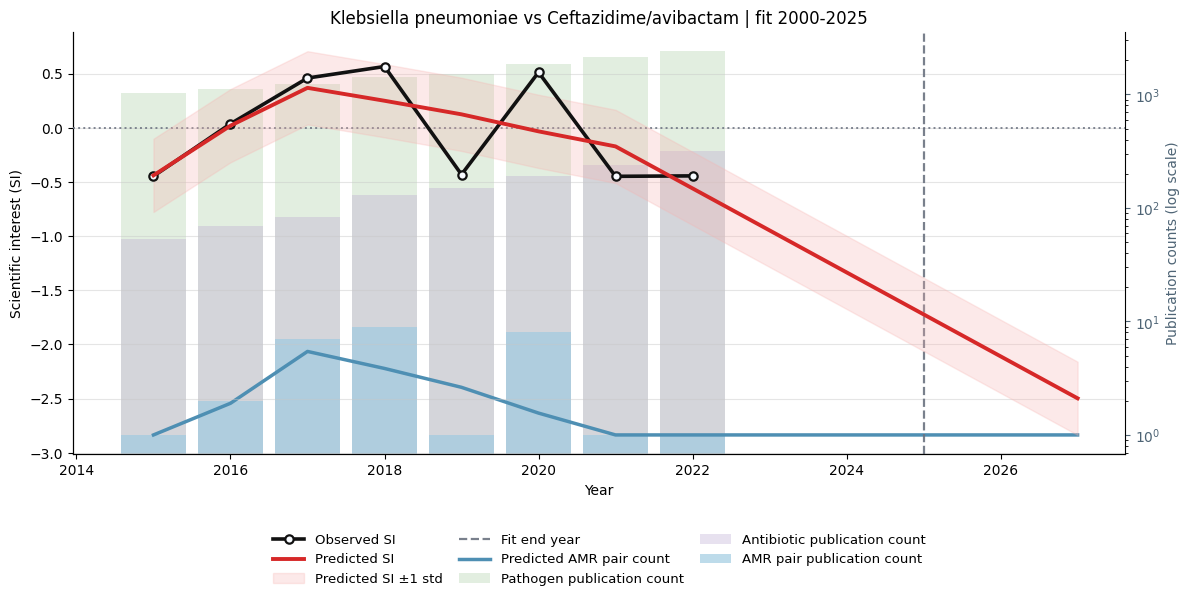

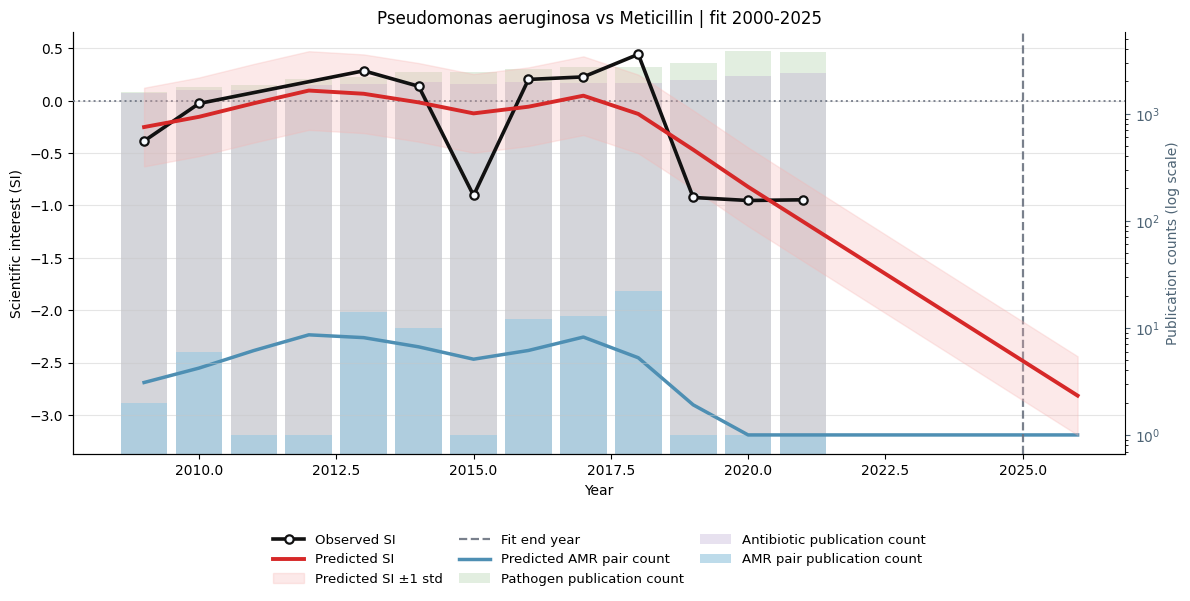

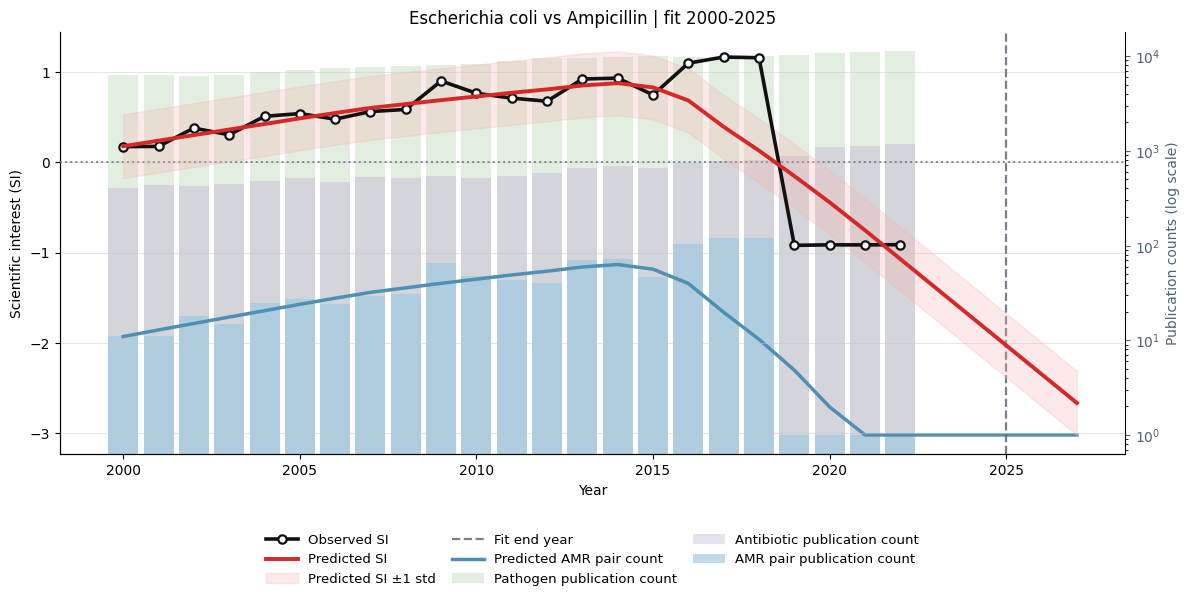

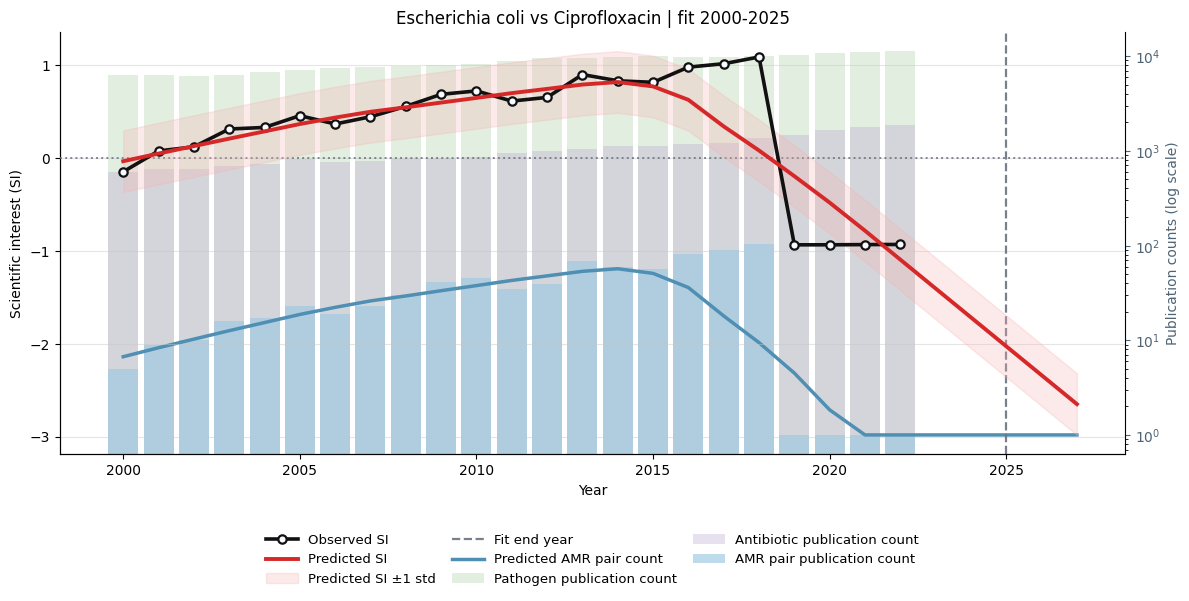

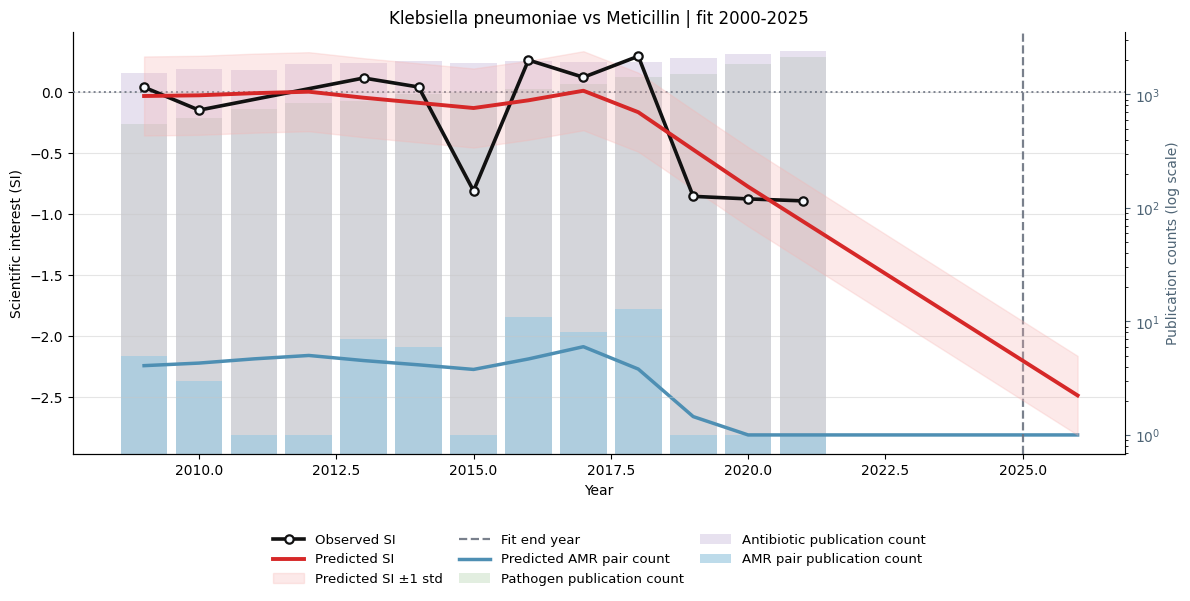

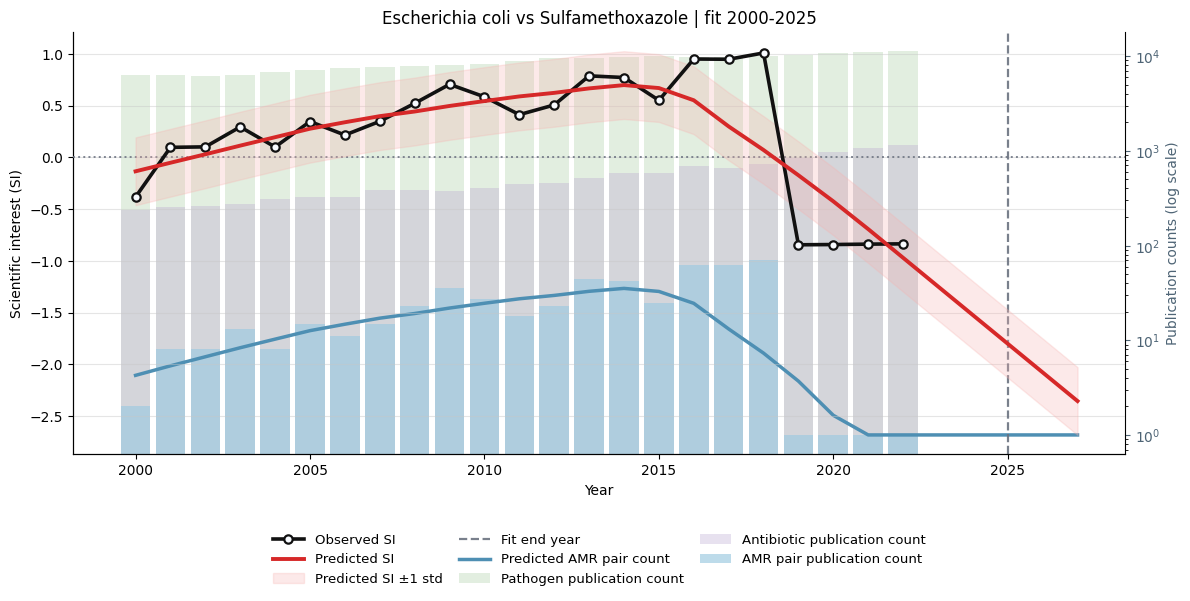

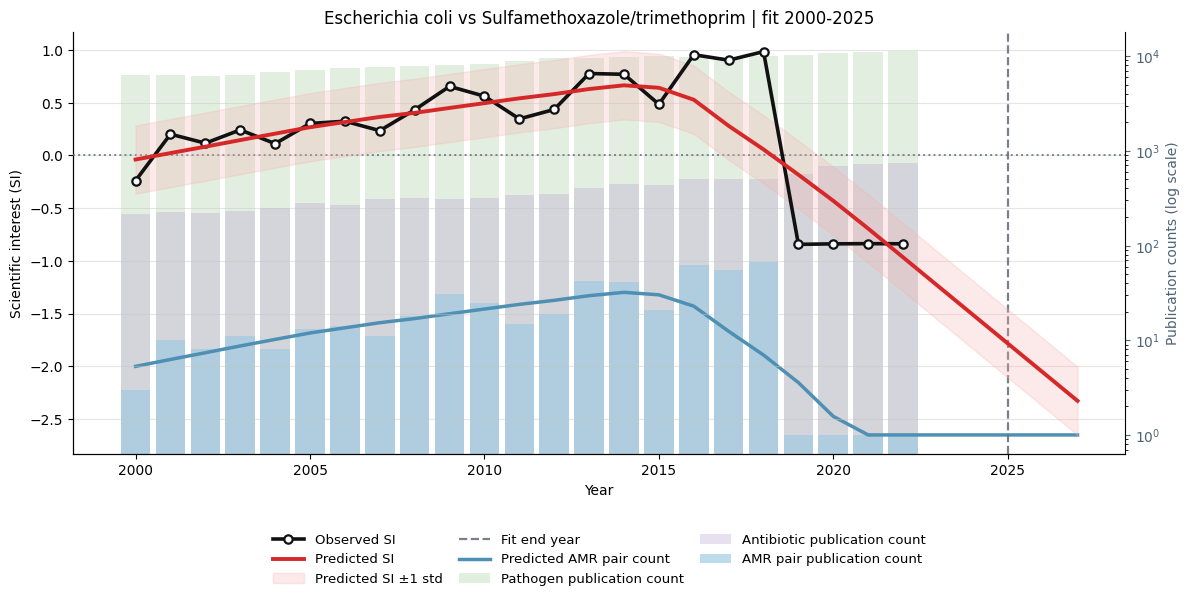

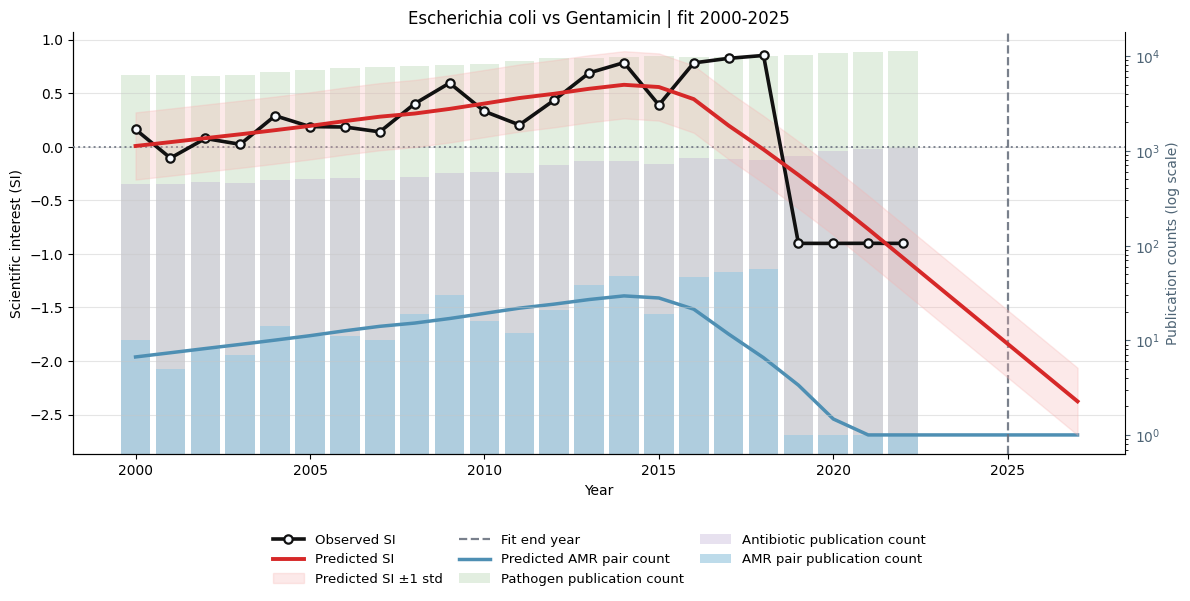

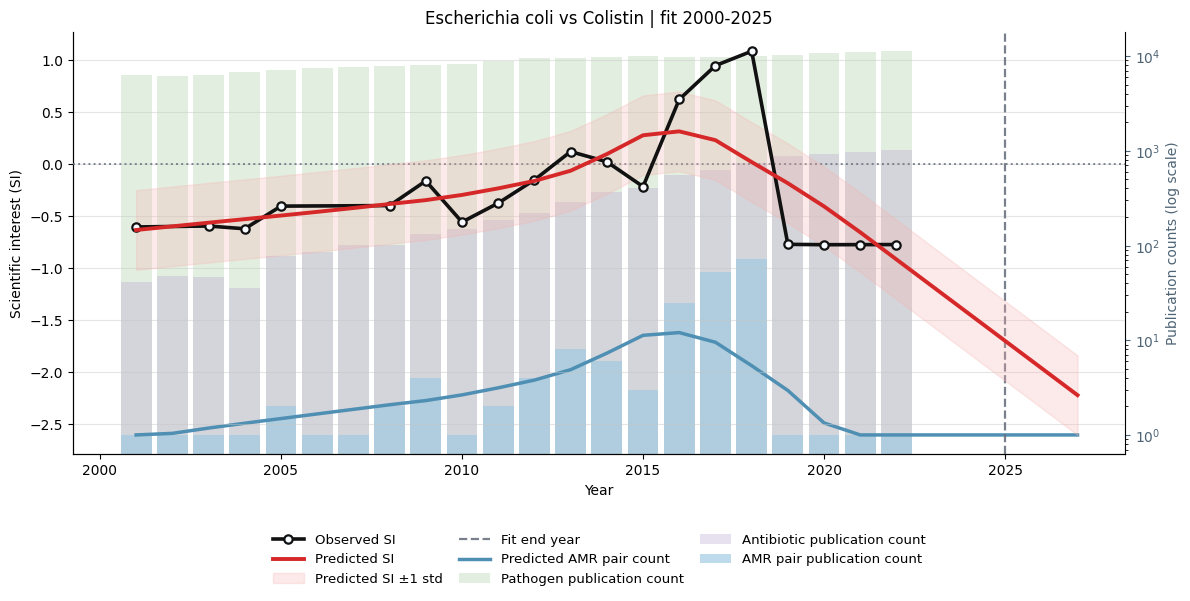

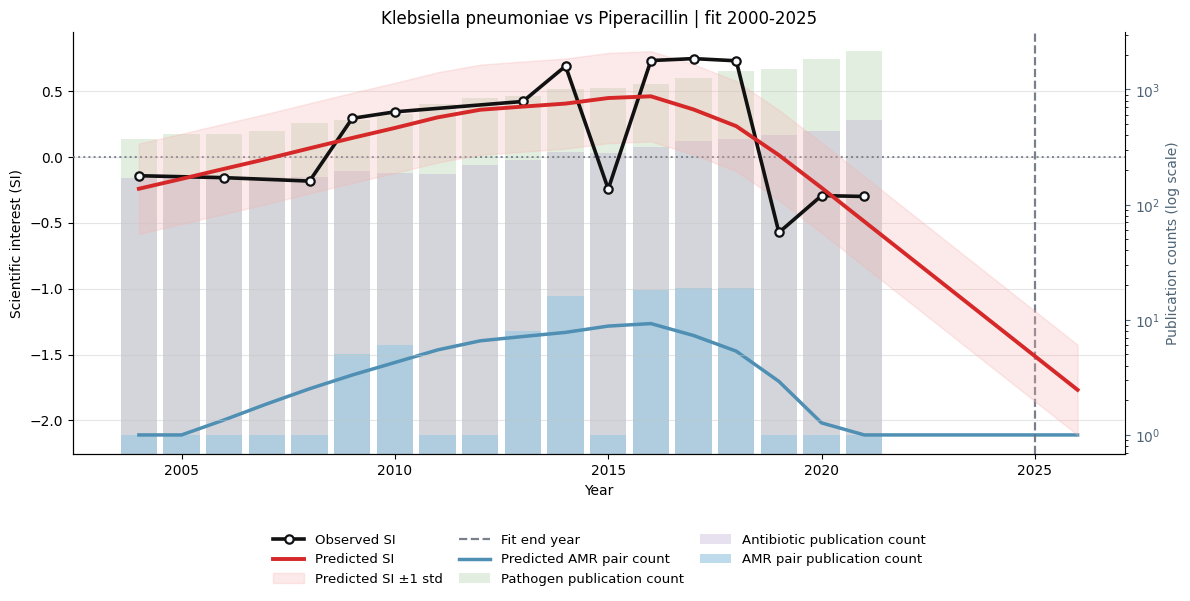

Saved 10 smoothed SI screen plots to /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/figures/decreasing_smoothed_si_plots


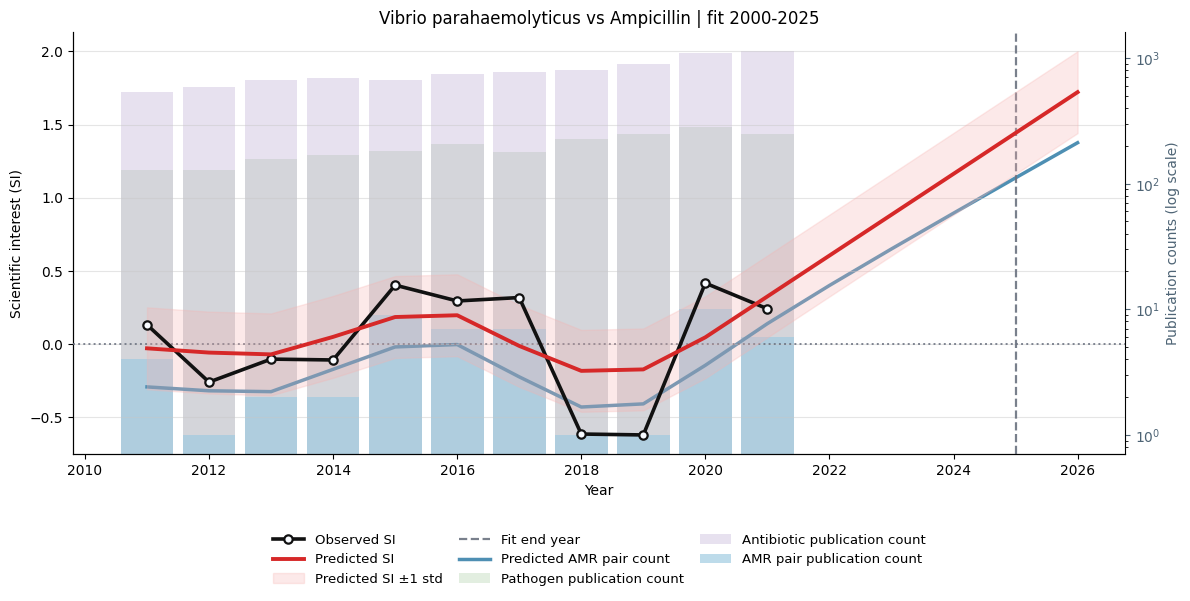

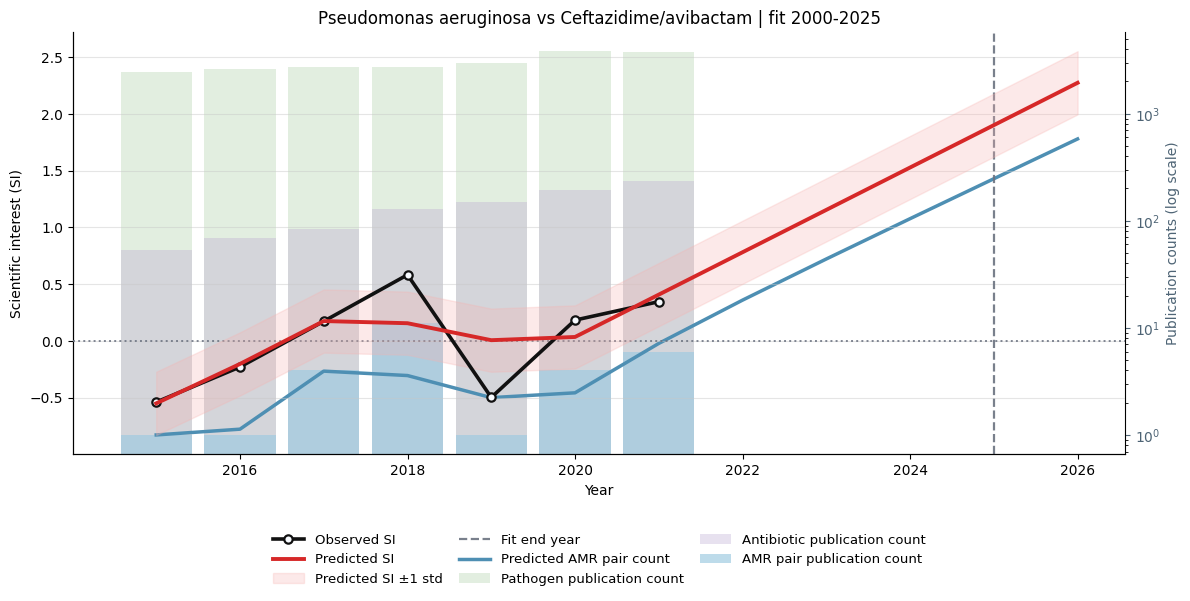

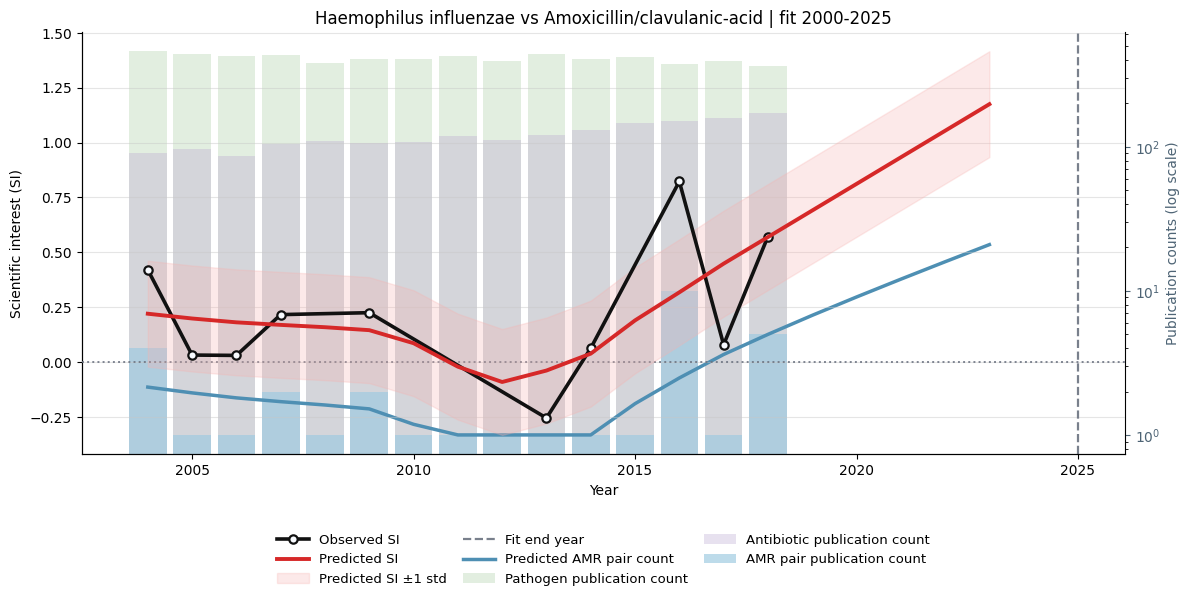

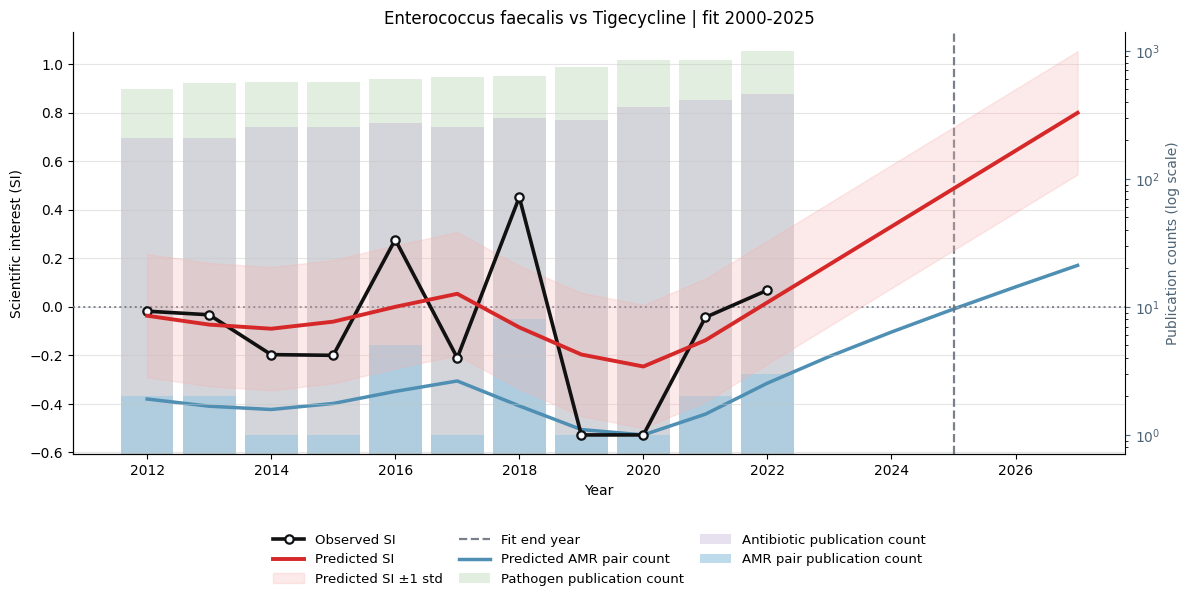

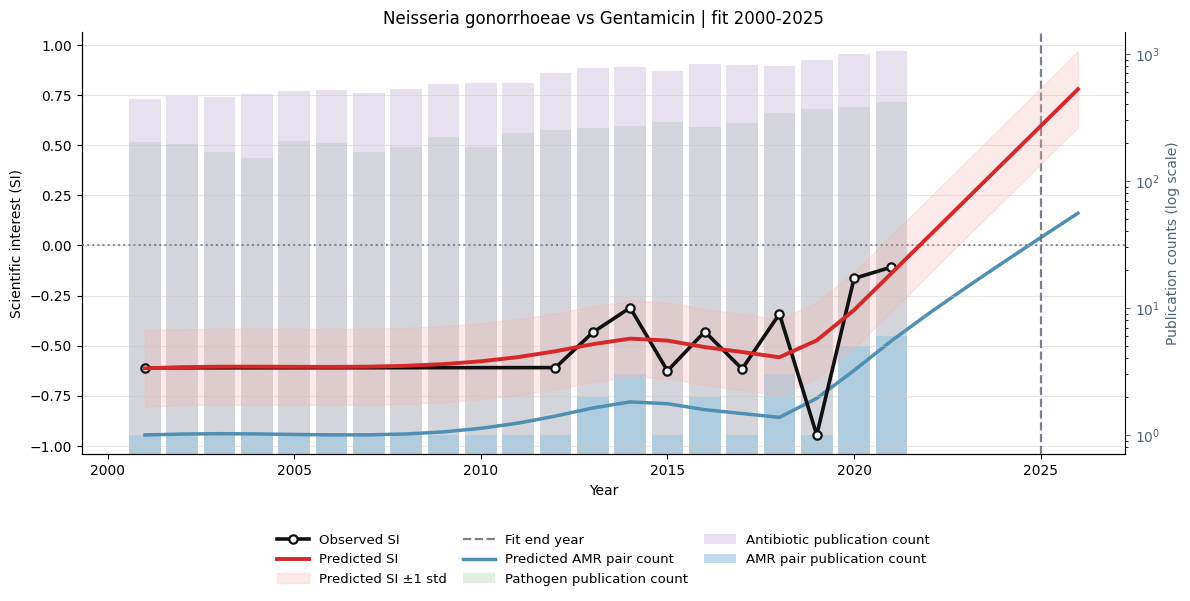

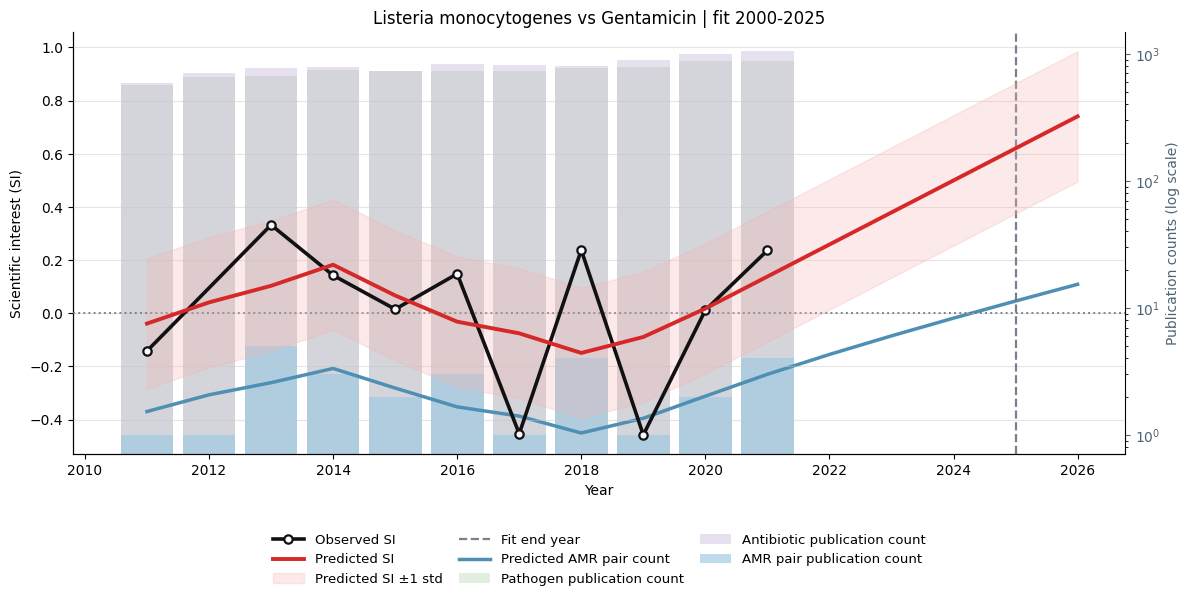

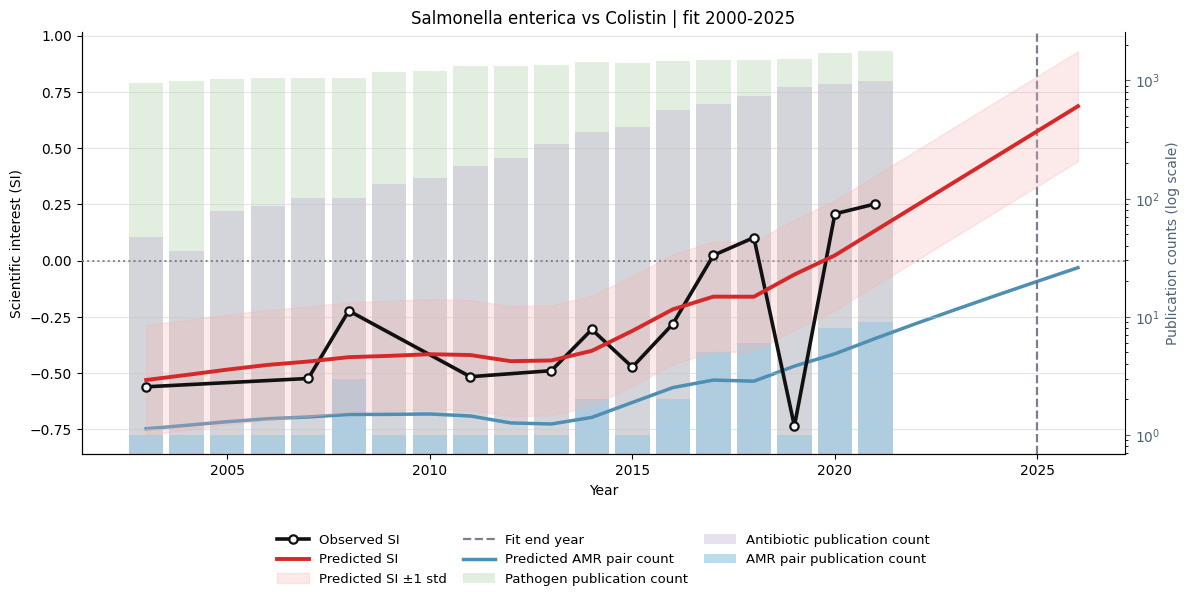

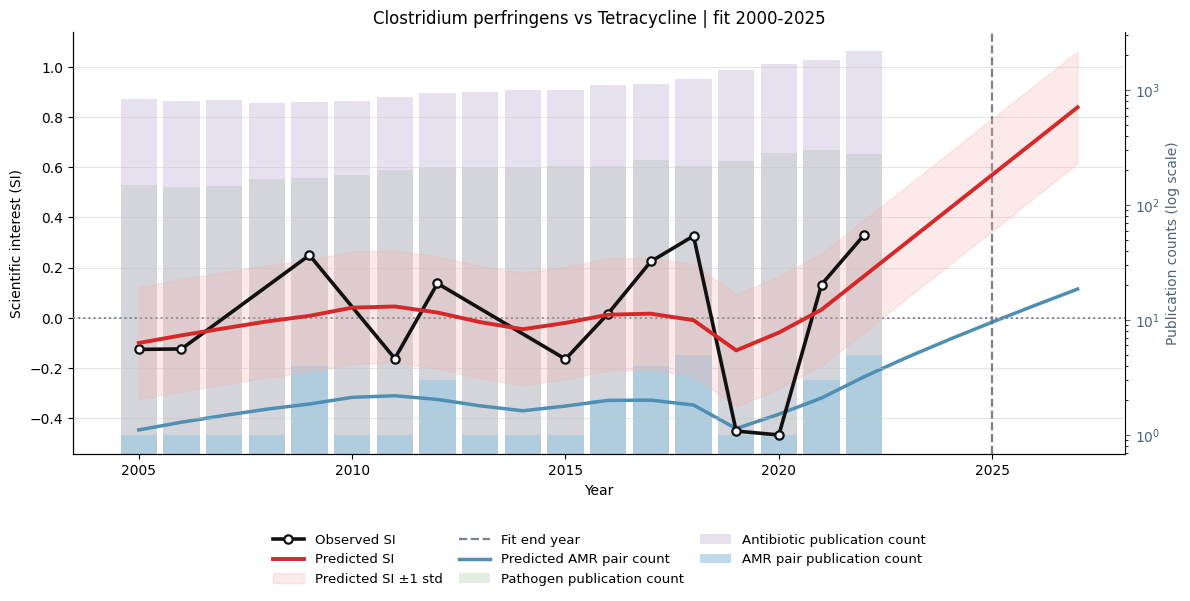

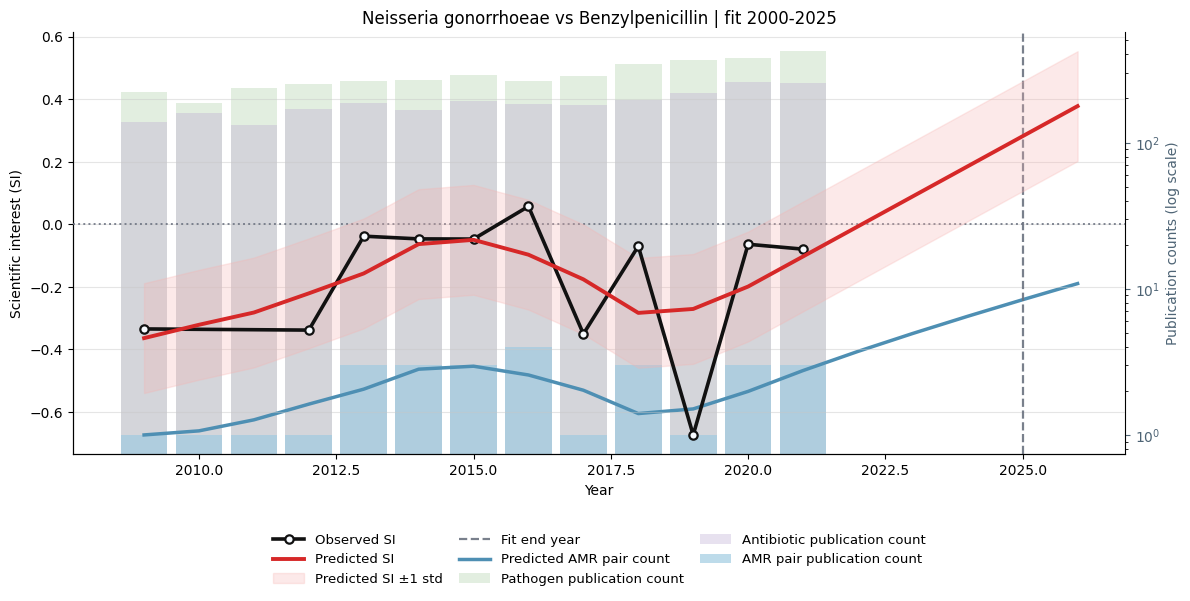

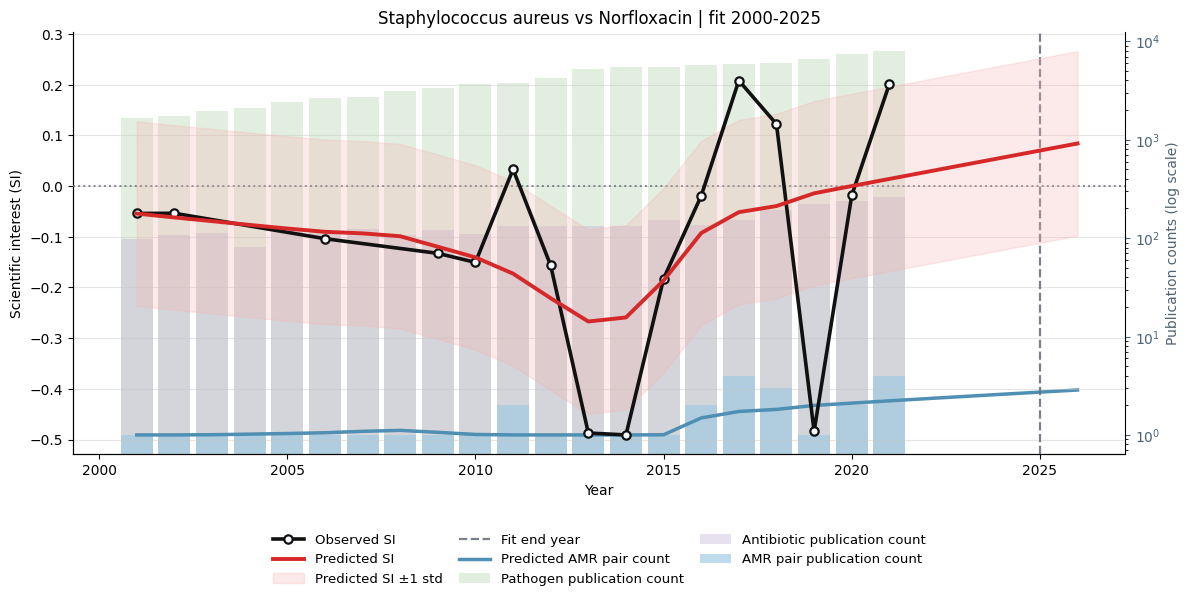

Saved 10 smoothed SI screen plots to /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/figures/convex_u_shaped_smoothed_si_plots


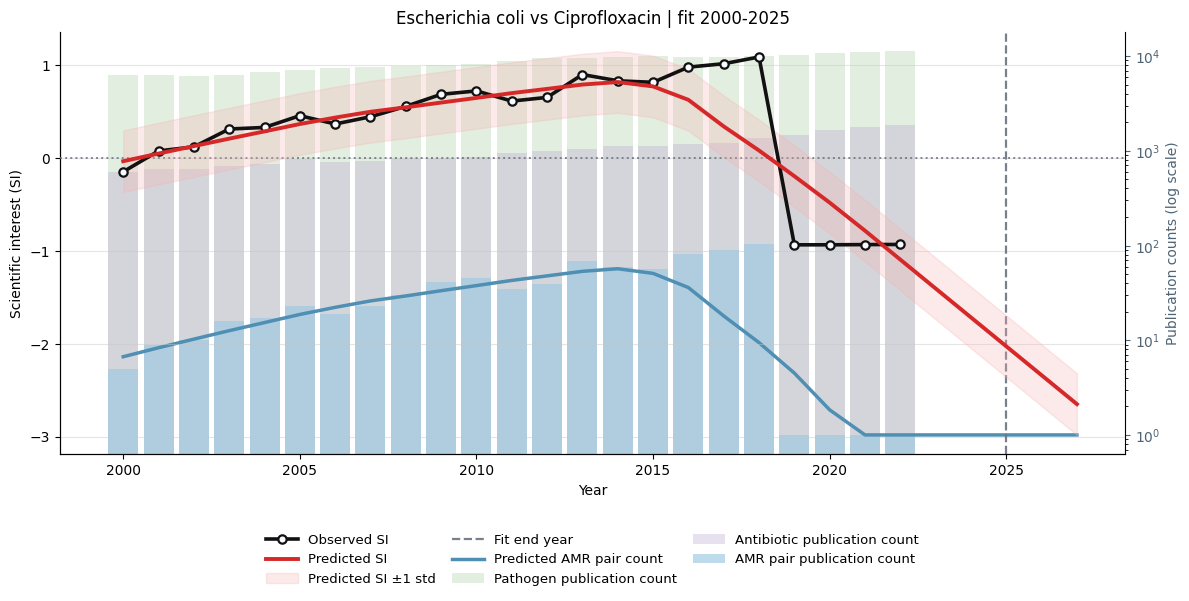

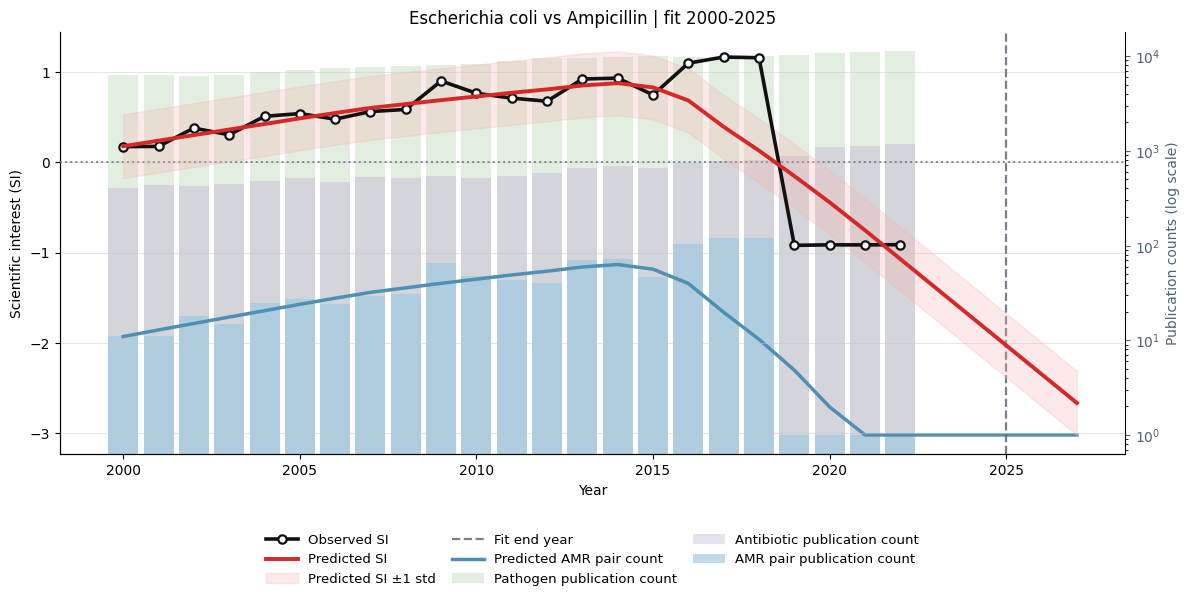

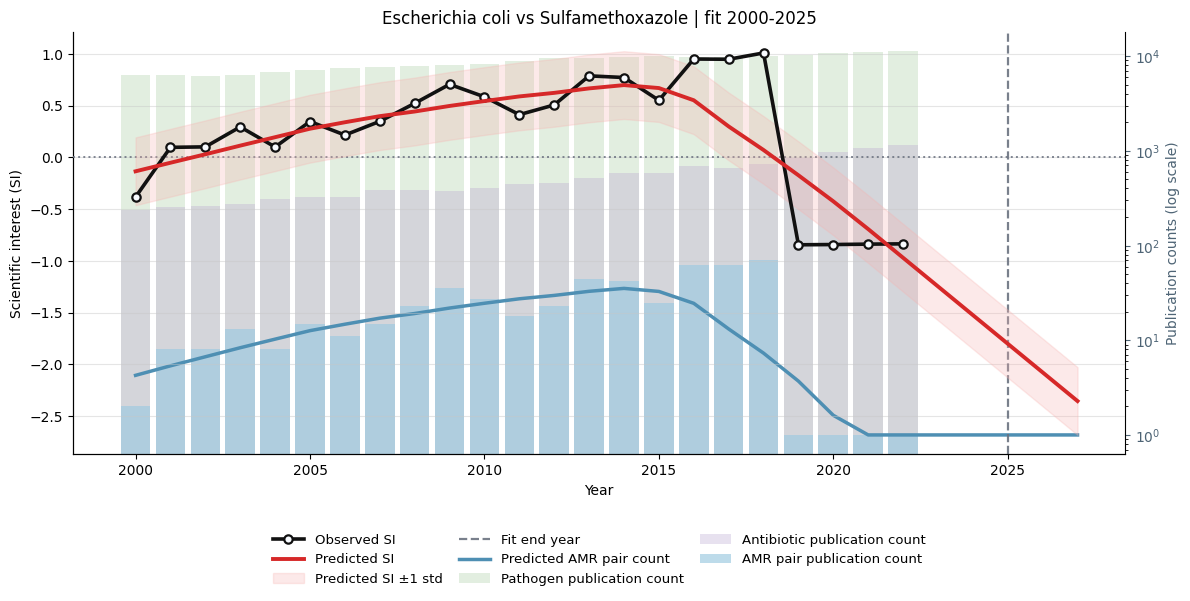

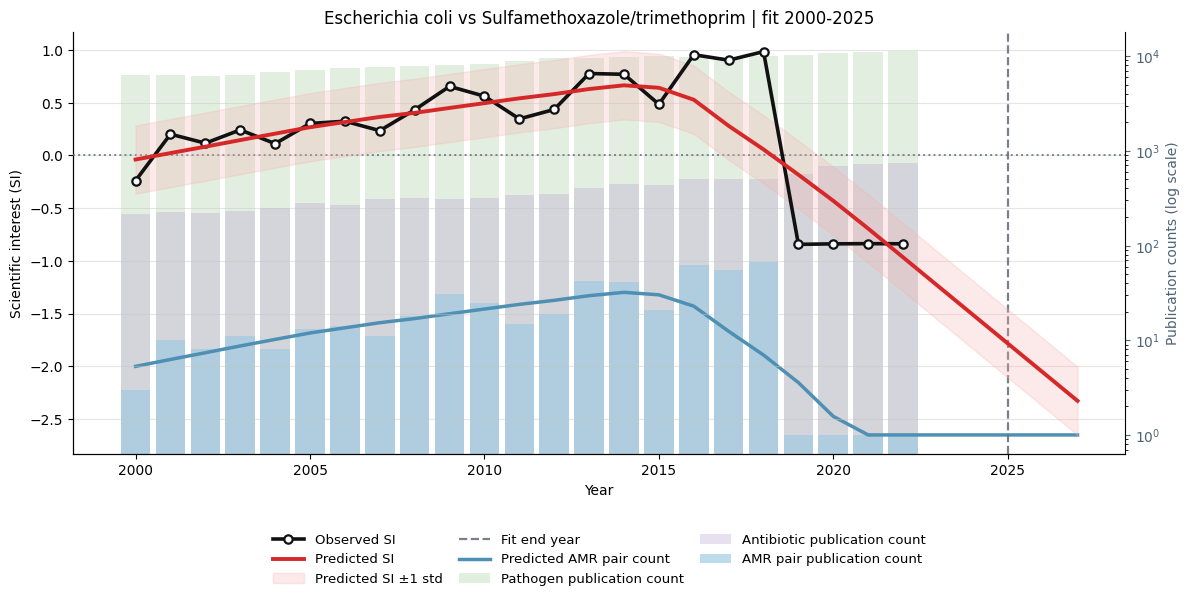

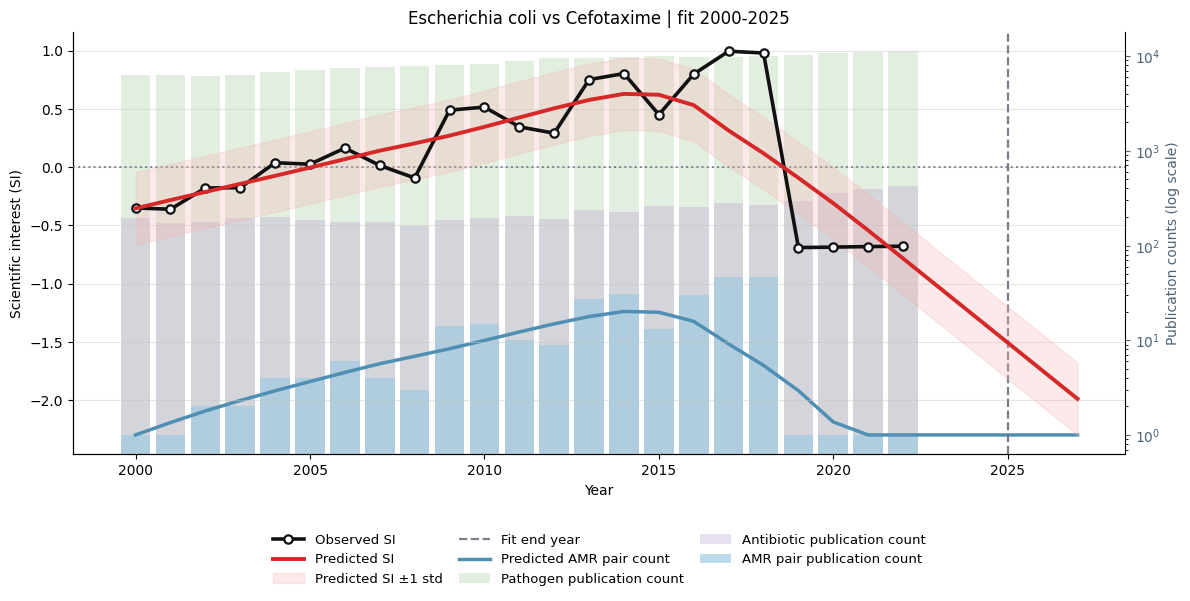

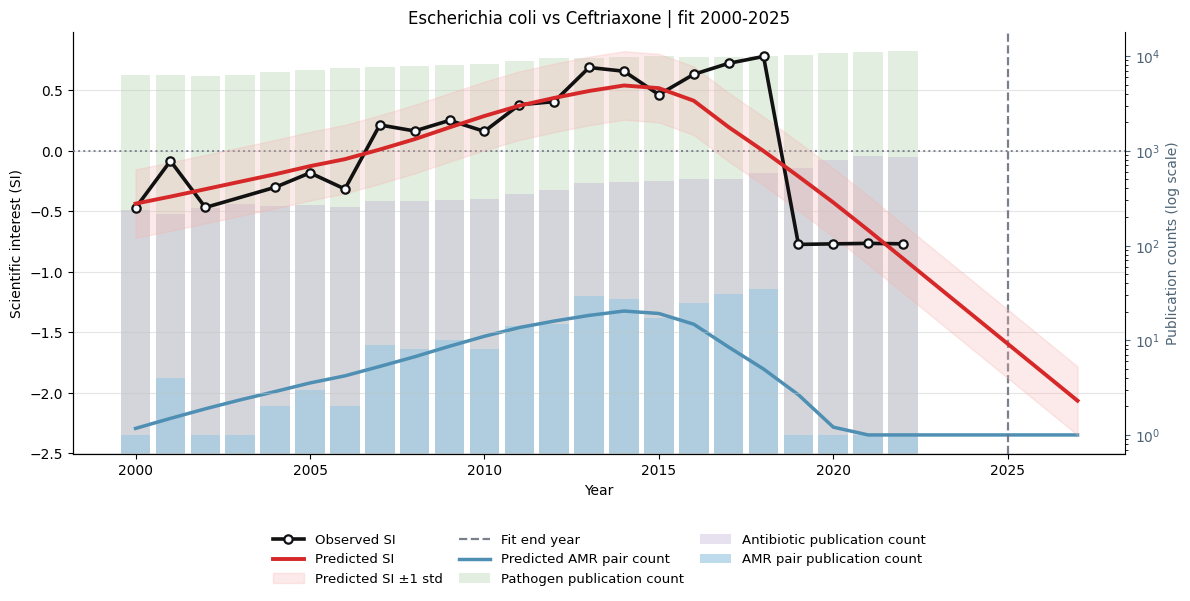

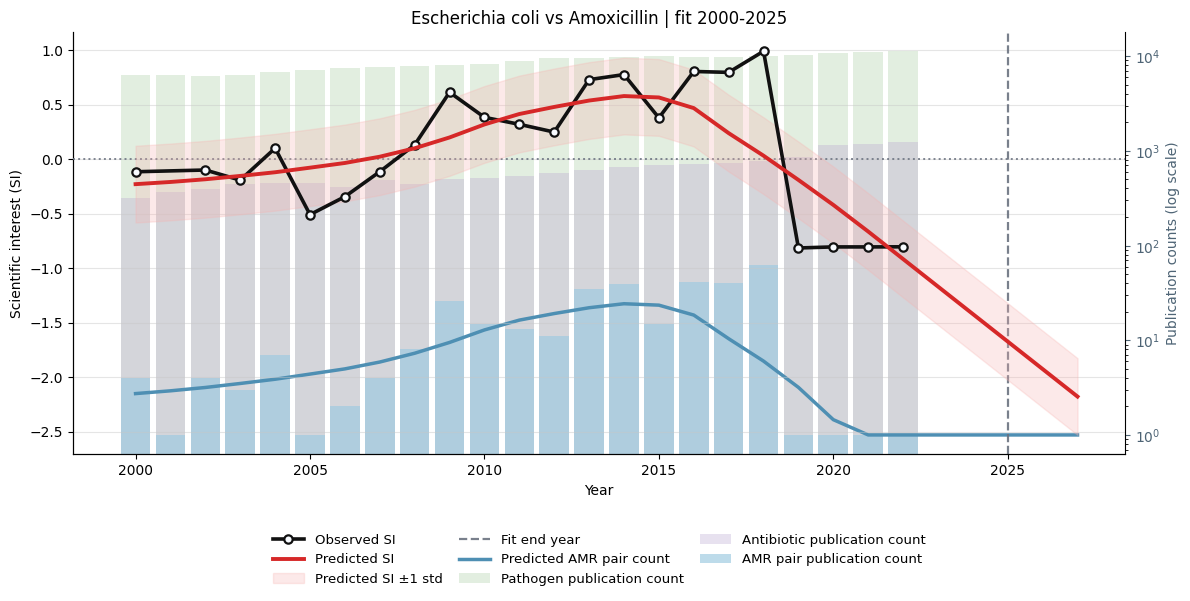

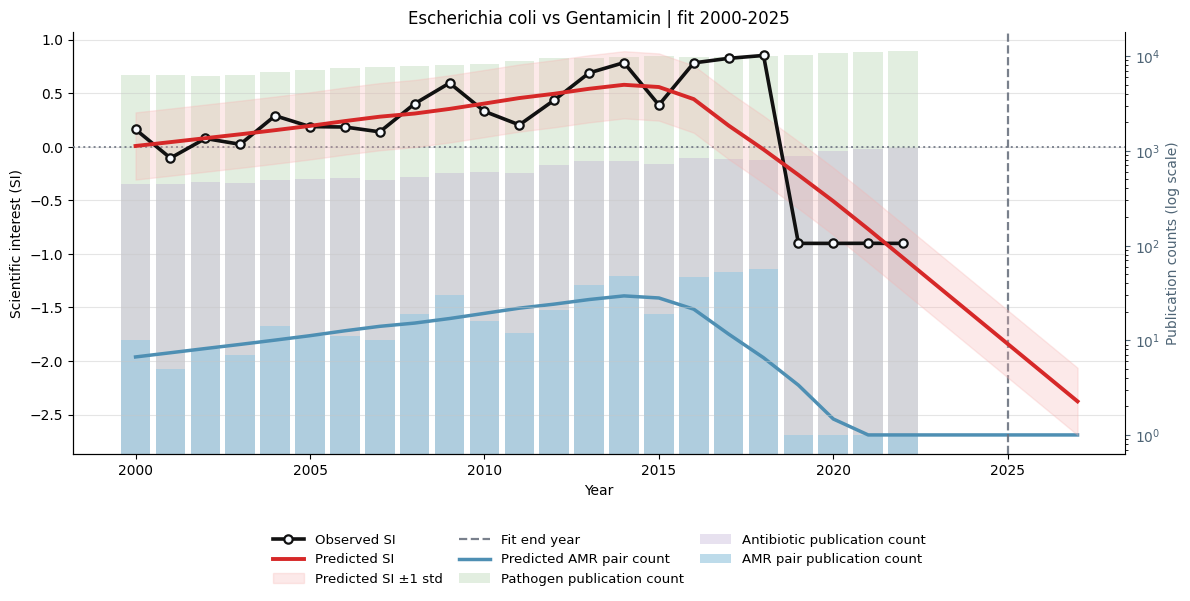

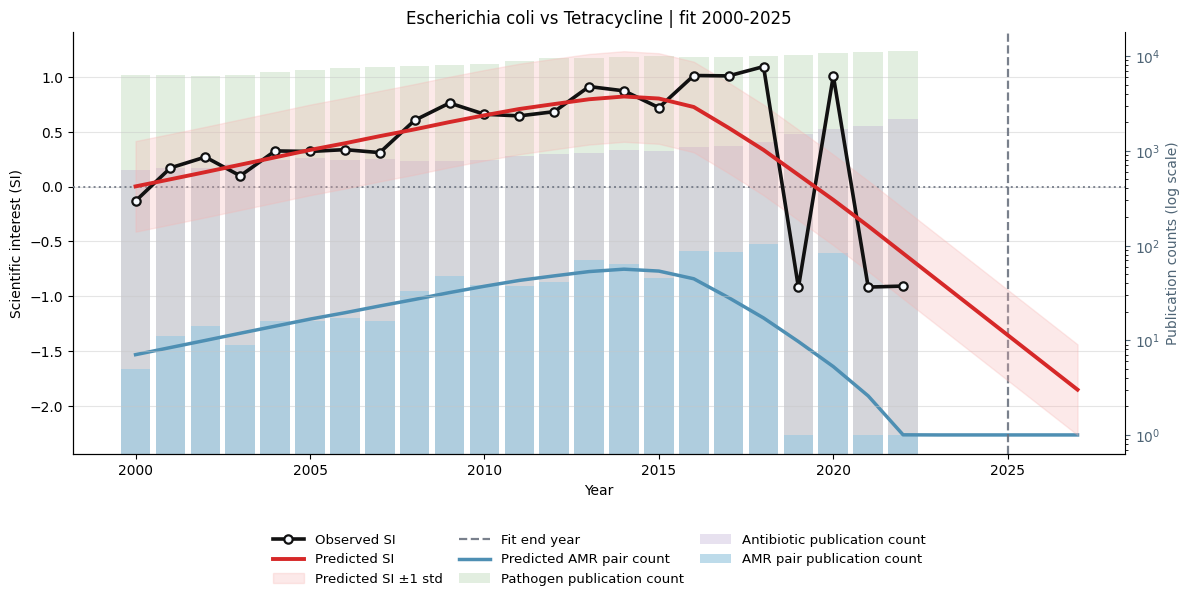

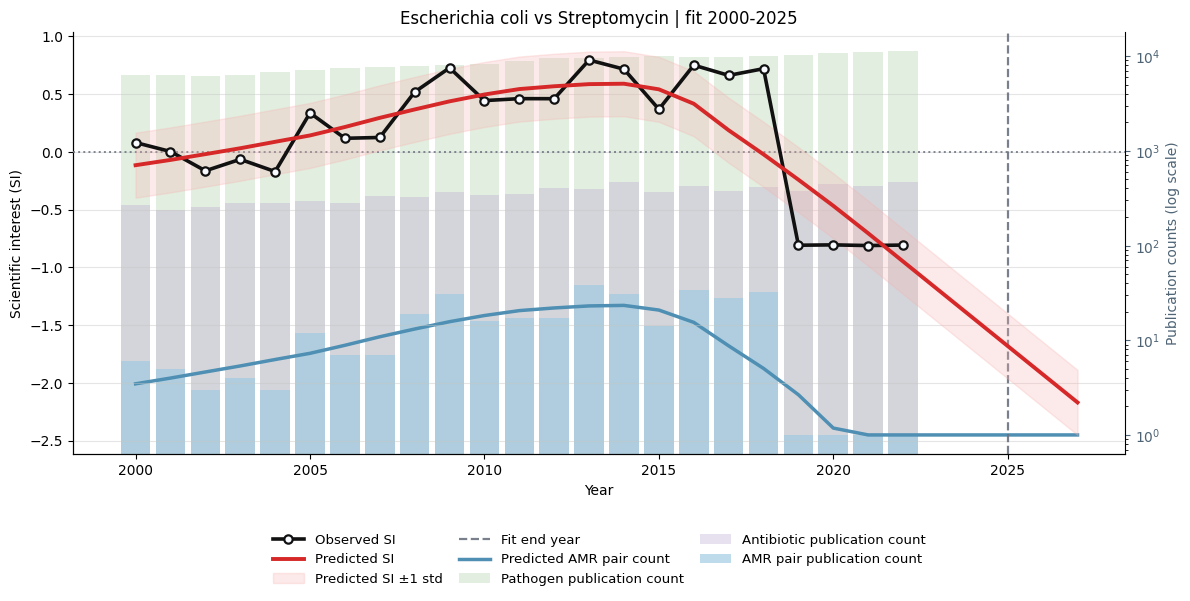

Saved 10 smoothed SI screen plots to /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/figures/concave_inverted_u_smoothed_si_plots


10

: 

In [ ]:
save_smoothed_si_screen_plots(
    screen_df=decreasing_smoothed_si_df,
    si_df=si_df,
    output_dir=DECREASING_SI_PLOT_DIR,
    fit_start_year=FIT_START_YEAR,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    pathogen_background_df=pathogen_bg_df,
    antibiotic_background_df=antibiotic_bg_model_df,
    max_plots=SHAPE_SCREEN_PLOT_COUNT,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
)

save_smoothed_si_screen_plots(
    screen_df=most_convex_smoothed_si_df,
    si_df=si_df,
    output_dir=CONVEX_SI_PLOT_DIR,
    fit_start_year=FIT_START_YEAR,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    pathogen_background_df=pathogen_bg_df,
    antibiotic_background_df=antibiotic_bg_model_df,
    max_plots=SHAPE_SCREEN_PLOT_COUNT,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
)

save_smoothed_si_screen_plots(
    screen_df=most_concave_smoothed_si_df,
    si_df=si_df,
    output_dir=CONCAVE_SI_PLOT_DIR,
    fit_start_year=FIT_START_YEAR,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    pathogen_background_df=pathogen_bg_df,
    antibiotic_background_df=antibiotic_bg_model_df,
    max_plots=SHAPE_SCREEN_PLOT_COUNT,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
)
